# Lab 07 – Evaluating Unsupervised Models: When Metrics Disagree

**Data Science Lab 83-554 · Bar-Ilan University · Dr. Alexandra Litinsky Simanovsky**

In the previous lab you chose a clustering and defended it. Today the question is the one behind that choice: **how do you decide that an unsupervised model is good, when different metrics, assumptions and goals disagree?**

**The story.** A field-biology team recorded frog calls in 59 recording sessions. Each session recorded **one calling frog**, with whatever microphone and placement the team had that night. Besides the calls, every session kept a few short **background segments** – the same microphone, no frog calling. The team wants to sort new recordings by species without listening to every one, and asks you which clustering to trust. You will first decide how to normalize the recordings, then compare internal metrics, stability, information criteria and three algorithms, and only then open a taxonomy the biologists kept hidden from you. Finally you will see how a score can improve for the wrong reason, test on sessions the model has never heard, and write them a recommendation.

The goal is not to discover one magic score. A clustering has no single "accuracy", and by the end you will be able to say what each number does and does not tell you.

| Block | Topic | Exercises | Time |
|---|---|---|---|
| 0 | Audit and a first look | 1–2 | ~15 min |
| 1 | Normalize by what? Microphones and recordings | 3–6 | ~35 min |
| 2 | Internal evaluation: K-Means | 7–9 | ~25 min |
| 3 | Stability: does the answer survive re-running? | 10–11 | ~15 min |
| 4 | Other algorithms: GMM, Ward and DBSCAN | 12–15 | ~35 min |
| 5 | Reveal the taxonomy: external evaluation | 16–21 | ~45 min |
| 6 | Leakage and new recording sessions | 22–24 | ~25 min |
| 7 | Find the bug | 25–27 | ~15 min |
| 8 | Integrated challenge: the evaluation report | 28 | ~20 min |
| 9 | Working with an LLM, critically | 29–30 | ~15 min |
| 10 | Further investigations ★ (extra) | 31–33 |  |

Plan: about 245 minutes.

**★ = extra.** Exercises marked ★ (all of Block 10) are extra practice: do them if you finish early. Whatever you do not finish in class, you finish on your own.

**How to work**
- Each exercise shows the **expected output** (a chart, a table, or a description of the result) under an empty cell. Write code that produces it, then run the cell – your output replaces the expected one, so save your own copy and keep the original open.
- Hints are collapsed under each exercise. Try first, open them only if you are stuck.
- Where an exercise says *explain*, write your answer in a short comment or a Markdown cell, in English or Hebrew. A number from your own output is part of a good answer.
- Exercises depend on each other and run **in order, once**: if a result looks strange, restart from the first cell instead of re-running a single cell.
- The first code cell is supplied: imports, `RANDOM_STATE`, `TSNE_ITER` and two helpers – `share_between` measures how much of the variance lies between groups, and `plot_sessions` draws a 2D map with the largest sessions in colour.
- Unless an exercise says otherwise, fit K-Means with `n_init=20, random_state=RANDOM_STATE`, so that your numbers match the expected ones.
- **Don't read ahead.** Make your choices in Blocks 1–4 before you look at the taxonomy, or the comparison in Block 5 means nothing.
- Cluster numbers are arbitrary, so compare groups and not their numbers. Expected outputs were produced with pandas 2.2 and scikit-learn 1.4. On other versions, some numbers can differ slightly – that is fine.
- Submit in pairs: the notebook and an identical PDF, with both names and IDs in the Markdown cell below this one.

**Data** (folder `data/`, next to this notebook)
- `frog_calls.csv` – call syllables: `sample_id`, `recording_session` and 22 acoustic coefficients `mfcc_01, …, mfcc_22` (MFCCs: a compact description of the sound's spectrum). `sample_id` and `recording_session` are metadata, not acoustic measurements.
- `session_background.csv` – 3–5 background segments per session: `recording_session`, `segment` and the same 22 coefficients, measured through the same microphone while no frog was calling.
- `frog_taxonomy_reveal.csv` – the biologists' reference taxonomy (family, genus, species, in coded names) for every `sample_id`. Open it **only from Block 5 on**.

Source: adapted from the UCI [Anuran Calls (MFCCs)](https://doi.org/10.24432/C5CC9H) dataset (J. Colonna, E. Nakamura, M. Cristo and M. Gordo, CC BY 4.0). The course staff took 6,000 of its syllables and changed them: a small jitter, a different simulated microphone per recording, simulated background segments, new session numbers and IDs, coded taxonomy names, and an export error.

**Student 1 (name + ID):** Amir Golan 216264333

**Student 2 (name + ID):** Idan Persky 215548512

In [45]:
import inspect
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from itertools import combinations
from IPython.display import display
from scipy.cluster.hierarchy import linkage, dendrogram
from scipy.optimize import linear_sum_assignment
from scipy.stats import entropy

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.mixture import GaussianMixture
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import (
    silhouette_score, silhouette_samples, calinski_harabasz_score, davies_bouldin_score,
    adjusted_rand_score, normalized_mutual_info_score, rand_score, mutual_info_score, classification_report
)
from sklearn.model_selection import GroupShuffleSplit, train_test_split
from threadpoolctl import threadpool_limits

threadpool_limits(2)  # keeps K-Means quick and avoids a memory-leak warning on Windows
RANDOM_STATE = 42
TSNE_ITER = {'max_iter': 1000} if 'max_iter' in inspect.signature(TSNE).parameters else {'n_iter': 1000}
sns.set_theme(style='whitegrid', context='notebook')


def share_between(Z, groups):
    """Share of the total variance of the rows of Z that lies between the group means:
    0 = all groups look alike on average, 1 = every row equals its group's mean."""
    Z = np.asarray(Z, dtype=float)
    group_means = pd.DataFrame(Z).groupby(np.asarray(groups)).transform('mean').to_numpy()
    return ((group_means - Z.mean(axis=0)) ** 2).sum() / ((Z - Z.mean(axis=0)) ** 2).sum()


def plot_sessions(ax, Z, sessions, title, top=8):
    """Scatter a 2D map: the `top` largest recording sessions in colour, all other rows in light grey."""
    sessions = np.asarray(sessions)
    largest = pd.Series(sessions).value_counts().index[:top]
    rest = ~np.isin(sessions, largest)
    ax.scatter(*Z[rest].T, c='lightgray', s=4)
    for s in largest:
        ax.scatter(*Z[sessions == s].T, s=5, label=f'session {s}')
    ax.set(title=title)
    ax.legend(fontsize=7, markerscale=3, ncol=2)

## Block 0 – Audit and a first look
Before comparing any scores, decide what may enter the model at all, and look at the data once.

### Exercise 1 – Audit the dataset

Load `data/frog_calls.csv` as `df`. In one compact inspection, report the shape, missing values, duplicate rows and duplicated `sample_id`s, the number of recording sessions and the number of rows per session (minimum, median, maximum). For every `mfcc_` column report its standard deviation and the share of rows at its most common value. Drop exact duplicate rows, and store the acoustic columns you will use as `feature_cols`.

**Explain:** Which columns don't enter the feature matrix, and why? Why is it safe to drop the duplicates here?

In [46]:
# Check for missing values and duplicated records before clustering.
# sample_id and recording_session are identifiers, not acoustic features.
# mfcc_01 is constant, so it cannot help separate calls either.
# Exact duplicate records repeat the same measurement and would give it extra weight.

from pathlib import Path
df = pd.read_csv('Data/frog_calls.csv')
# Shape
print('Shape:', df.shape)

# Missing values per column
print('Missing values per column:\n', df.isna().sum().to_string())

# Amount of duplicates
print('Exact duplicates:', df.duplicated().sum())

# Smaple id duplicates
print('Repeated sample IDs:', df.sample_id.duplicated().sum())

# Session value counts 
session_sizes = df.recording_session.value_counts()
print('Sessions:', len(session_sizes), '| rows/session min, median, max:',
      session_sizes.min(), session_sizes.median(), session_sizes.max())
mfcc_cols = [c for c in df if c.startswith('mfcc_')]
audit = pd.DataFrame({'std': df[mfcc_cols].std(),
                      'most_common_share': [df[c].value_counts(normalize=True, dropna=False).max() for c in mfcc_cols]})
display(audit.round(4))
# Removing duplicates and sample_id 
df = df.drop_duplicates().reset_index(drop=True)
df = df.drop('sample_id',axis=1)
feature_cols = [c for c in mfcc_cols if df[c].nunique() > 1]
print('After cleaning:', df.shape, '| useful MFCCs:', len(feature_cols))

Shape: (6025, 24)
Missing values per column:
 sample_id            0
recording_session    0
mfcc_01              0
mfcc_02              0
mfcc_03              0
mfcc_04              0
mfcc_05              0
mfcc_06              0
mfcc_07              0
mfcc_08              0
mfcc_09              0
mfcc_10              0
mfcc_11              0
mfcc_12              0
mfcc_13              0
mfcc_14              0
mfcc_15              0
mfcc_16              0
mfcc_17              0
mfcc_18              0
mfcc_19              0
mfcc_20              0
mfcc_21              0
mfcc_22              0
Exact duplicates: 25
Repeated sample IDs: 25
Sessions: 59 | rows/session min, median, max: 2 43.0 396


,std,most_common_share
mfcc_01,0.0681,0.9643
mfcc_02,0.3061,0.0005
mfcc_03,0.3574,0.0003
mfcc_04,0.2406,0.0003
mfcc_05,0.2427,0.0005
mfcc_06,0.1722,0.0003
mfcc_07,0.2406,0.0003
mfcc_08,0.1484,0.0003
mfcc_09,0.2591,0.0003
mfcc_10,0.1858,0.0003


After cleaning: (6000, 23) | useful MFCCs: 22


**Notes:** `sample_id` and `recording_session` are metadata, not sound features. `mfcc_01` is constant, so it cannot separate calls. The 25 exact duplicate records add no new measurements; removing them avoids counting those calls twice.

<details><summary><b>Hint 1</b></summary>

`df[c].value_counts(normalize=True).iloc[0]` is the share of rows at the most common value of column `c`.

</details>
<details><summary><b>Hint 2</b></summary>

A coefficient that has the same value in almost every row can't help to tell calls apart.

</details>

### Exercise 2 – Global standardization and a first map

Standardize `feature_cols` with `StandardScaler` (`X_global`). Fit PCA, report how many components reach **90%** and **95%** of the variance, and plot the cumulative explained variance. Then plot the first two components with `plot_sessions` (the eight largest sessions in colour). Store the session of every row as `sessions`.

**Explain:** What structure do you see on the map, and what does it seem to follow?

PCs to 90%: 14 | to 95%: 17


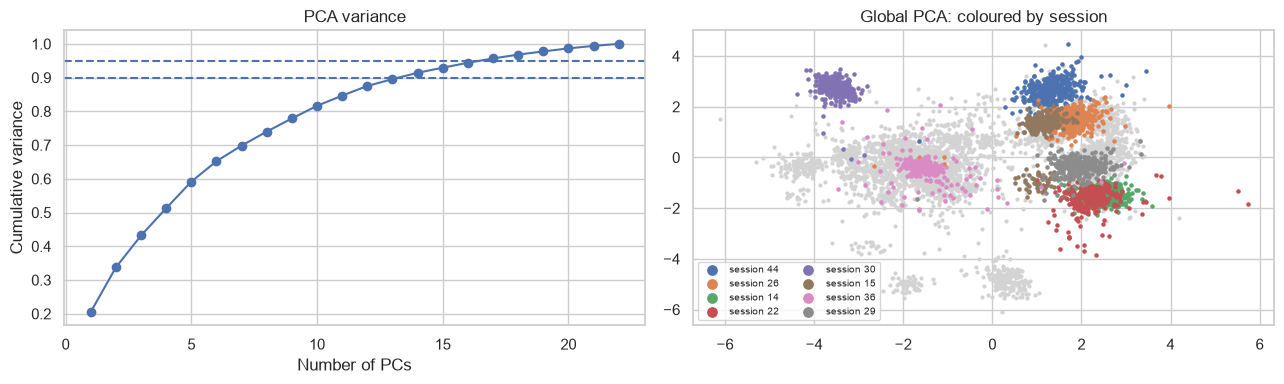

In [47]:
# Standardize the acoustic columns before PCA so large-scale features do not dominate.
# The 2D projection has patches that follow recording sessions.
# This could be frog identity, the recording setup, or both; PCA cannot tell us yet.

sessions = df.recording_session.to_numpy()
X_global = StandardScaler().fit_transform(df[feature_cols]) # Standardize feature_cols
pca_global = PCA(random_state=RANDOM_STATE).fit(X_global) # Firting pca
X_pca_global = pca_global.transform(X_global)
cum = np.cumsum(pca_global.explained_variance_ratio_)
# Amount of components that reach above 90%, 95%
print('PCs to 90%:', np.searchsorted(cum, .90) + 1, '| to 95%:', np.searchsorted(cum, .95) + 1) 
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].plot(np.arange(1, len(cum) + 1), cum, marker='o')
ax[0].axhline(.9, ls='--'); ax[0].axhline(.95, ls='--')
ax[0].set(xlabel='Number of PCs', ylabel='Cumulative variance', title='PCA variance')
plot_sessions(ax[1], X_pca_global[:, :2], sessions, 'Global PCA: coloured by session')
plt.tight_layout(); plt.show()

**Notes:** The PCA map shows session-shaped patches. They could come from the frog or the microphone, so the picture alone does not tell us which.

<details><summary><b>Hint 1</b></summary>

`np.searchsorted(cum, .90) + 1` is the number of components that reach 90%.

</details>
<details><summary><b>Hint 2</b></summary>

`plot_sessions(ax, Z[:, :2], sessions, 'title')` with `sessions = df.recording_session.to_numpy()`.

</details>

## Block 1 – Normalize by what? Microphones and recordings
Every recording reaches you through a microphone, and in MFCCs a microphone adds roughly **the same offset to every call of that recording**. Removing it is a normalization – but normalizing by the wrong thing can remove the signal itself. In this block you decide, **without any labels**, what to subtract.

### Exercise 3 – What does a global clustering follow?

Fit K-Means `k=10` on `X_global`. Report the NMI between the clusters and `recording_session`, the share of the variance that lies between sessions (`share_between`), the number of sessions in each cluster, and the median share of a session's calls that fall into its main cluster. Draw a heatmap of the share of each session's calls in each cluster.

**Explain:** The clusters follow the sessions closely. Each session is one frog – so is this clustering about frogs or about microphones? Can you tell from this exercise alone?

NMI with session: 0.717
Variance between sessions: 0.834
Sessions in each cluster:
 0    15
1    29
2     4
3    14
4    16
5     5
6    12
7     7
8     3
9    19
Median dominant-cluster share per session: 0.984


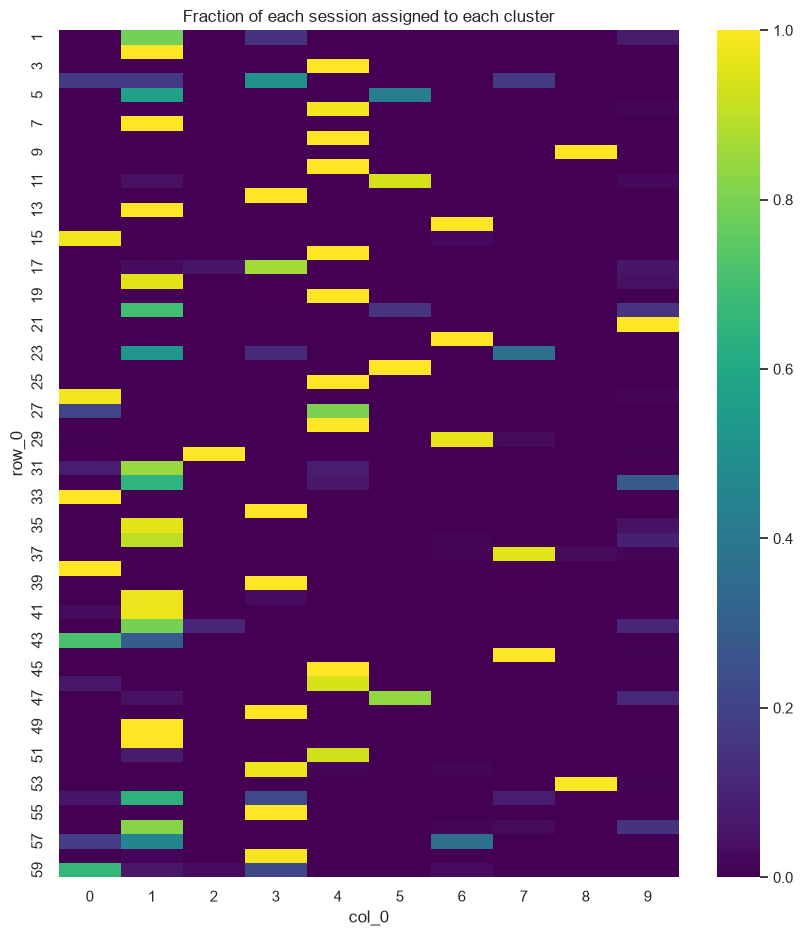

In [48]:
# Compare K-Means groups with recording sessions, not just their visual appearance.
# Strong session agreement does not prove whether the model picked up frogs or microphones:
# every session is one frog, so those two explanations are still mixed together.

km_global = KMeans(n_clusters=10, n_init=20, random_state=RANDOM_STATE)
lab_global = km_global.fit_predict(X_global)
shares = pd.crosstab(sessions, lab_global, normalize='index')
print('NMI with session:', round(normalized_mutual_info_score(sessions, lab_global), 3))
print('Variance between sessions:', round(share_between(X_global, sessions), 3))
print('Sessions in each cluster:\n', pd.Series(sessions).groupby(lab_global).nunique().to_string())
print('Median dominant-cluster share per session:', round(shares.max(axis=1).median(), 3))
plt.figure(figsize=(10, 11))
sns.heatmap(shares, cmap='viridis', vmin=0, vmax=1)
plt.title('Fraction of each session assigned to each cluster'); plt.show()

**Notes:** The clusters strongly track recordings, but each session contains one frog. We need the background measurements to separate the two explanations.

<details><summary><b>Hint 1</b></summary>

`pd.crosstab(sessions, labels, normalize='index')` gives, for every session, the share of its calls in each cluster.

</details>
<details><summary><b>Hint 2</b></summary>

`pd.Series(sessions).groupby(labels).nunique()` counts the sessions in each cluster.

</details>

### Exercise 4 – Listen to the silence

Load `data/session_background.csv` as `background` and average its segments per session (`background_mean`, indexed by session). For every feature, compute the correlation **across sessions** between the session's mean call and its mean background, and the ratio between the background's and the calls' between-session variance. Plot the session means of the calls against the session means of the background for `mfcc_02` and `mfcc_05` (one point per session), and a bar chart of the 21 correlations.

**Explain:** The background contains no frog. Why do the backgrounds differ between sessions at all? What does a strong correlation between a session's calls and its silence tell you about the patches in Exercise 2?

,call_background_corr,background_to_call_variance
mfcc_01,NaN,0.000
mfcc_02,0.699,0.614
mfcc_03,0.686,0.395
mfcc_04,0.767,0.424
mfcc_05,0.754,0.412
mfcc_06,0.757,0.554
mfcc_07,0.786,0.440
mfcc_08,0.527,0.550
mfcc_09,0.754,0.558
mfcc_10,0.697,0.463


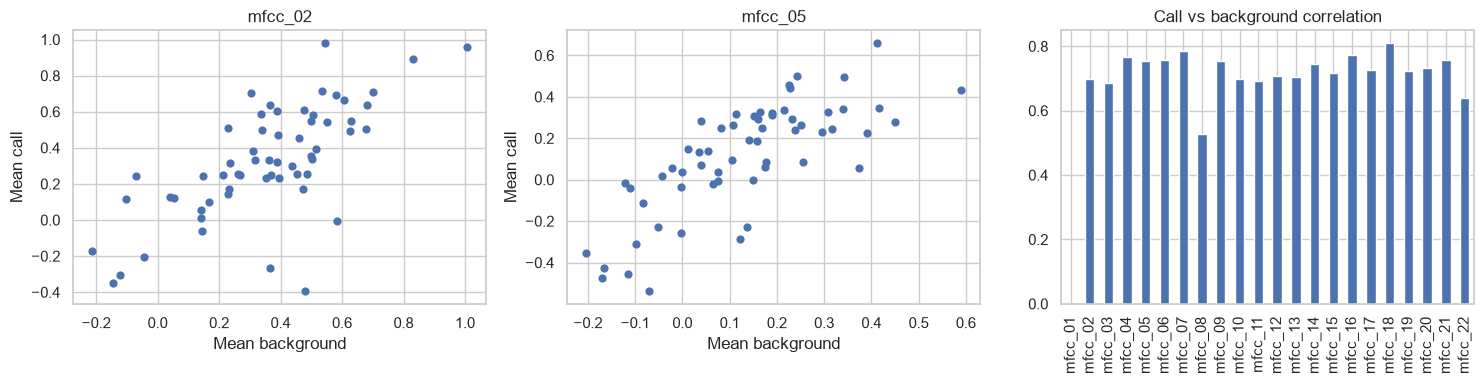

In [49]:
# Compare each session's average frog call with the background recorded in silence.
# The background has no frog calls; matching trends suggest microphone/environment effects.
# Correlation alone is evidence of a recording effect, not proof of its cause.

# Loading data
background = pd.read_csv('Data/session_background.csv')
# Defining background mean
background_mean = background.groupby('recording_session')[feature_cols].mean()
# Computing the correlation across sessions
call_mean = df.groupby('recording_session')[feature_cols].mean().loc[background_mean.index]
bg_correlations = pd.Series({c: call_mean[c].corr(background_mean[c]) for c in feature_cols})
bg_variance_ratio = background_mean.var() / call_mean.var()
bg_check = pd.DataFrame({'call_background_corr': bg_correlations,
                         'background_to_call_variance': bg_variance_ratio})
display(bg_check.round(3))
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
for axis, col in zip(ax[:2], ['mfcc_02', 'mfcc_05']):
    axis.scatter(background_mean[col], call_mean[col], s=24)
    axis.set(xlabel='Mean background', ylabel='Mean call', title=col)
bg_correlations.plot.bar(ax=ax[2], title='Call vs background correlation')
plt.tight_layout(); plt.show()

**Notes:** The silence contains no frog, so differences in its MFCCs point to microphone or environmental effects. Similar patterns in calls suggest the session patches are partly recording artefacts.

<details><summary><b>Hint 1</b></summary>

`background.groupby('recording_session')[feature_cols].mean()`; align the calls' session means to the same index with `.loc[background_mean.index]`.

</details>
<details><summary><b>Hint 2</b></summary>

If the silence of a session is high on `mfcc_05`, and its calls are high too, what do the calls and the silence have in common?

</details>

### Exercise 5 – Three ways to normalize – compare them before any labels

Build three matrices, each followed by `StandardScaler`:
- `X_global`: as in Exercise 2;
- `X_session`: each call minus **its own session's mean call** (per-recording mean normalization, standard in speech processing);
- `X_background`: each call minus **its session's mean background** from Exercise 4.

For each, report `share_between`, the silhouette of K-Means `k=10` (`sample_size=2000, random_state=RANDOM_STATE`) and the NMI between the clusters and `recording_session`. Store the table as `normalization_eval` and draw the first two PCA components of each with `plot_sessions`. Keep the three matrices in a dictionary `candidates`.

**Explain:** Which normalization removes the most session structure, and why is that *not* automatically the best one here? Why does the silhouette prefer the global version?

,between_session,silhouette,session_nmi
normalization,,,
global,0.834,0.272,0.717
session mean,0.000,0.056,0.137
background,0.727,0.280,0.581


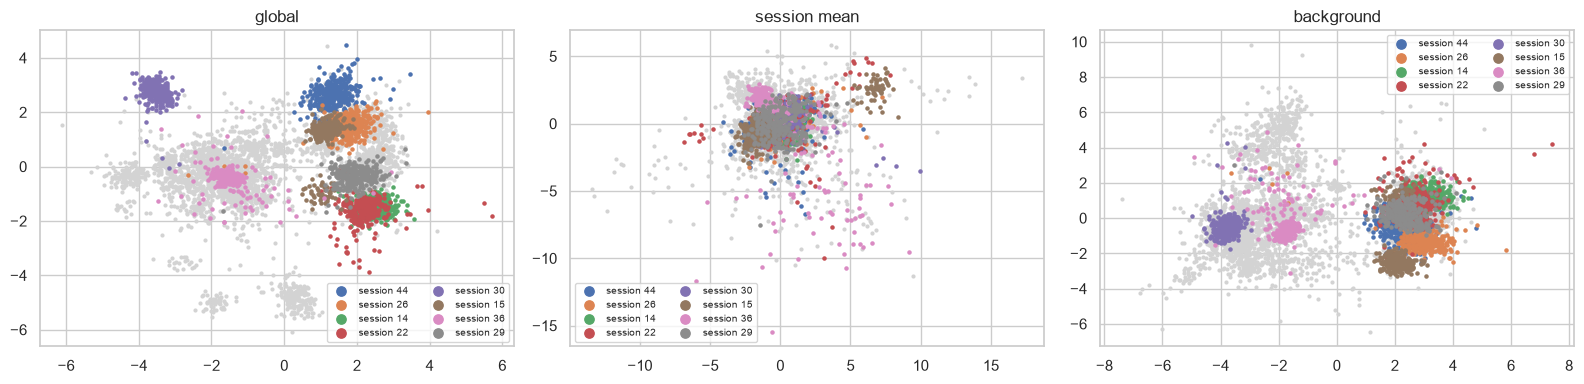

In [50]:
# Test global scaling, session-mean subtraction, and background subtraction fairly.
# Session-mean subtraction removes recording offsets but also part of each frog's sound.
# A high silhouette alone can be misleading if it mostly reflects session differences.

# Creating X_Session
call_values = df[feature_cols].to_numpy()
X_session = StandardScaler().fit_transform(
    call_values - df.groupby('recording_session')[feature_cols].transform('mean').to_numpy())
# Creating X_background
X_background = StandardScaler().fit_transform(
    call_values - background_mean.loc[sessions, feature_cols].to_numpy())

candidates = {'global': X_global, 'session mean': X_session, 'background': X_background}
rows = []

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, (name, X) in zip(axes, candidates.items()):
    labels = KMeans(10, n_init=20, random_state=RANDOM_STATE).fit_predict(X)
    rows.append({'normalization': name, 'between_session': share_between(X, sessions),
                 'silhouette': silhouette_score(X, labels, sample_size=2000, random_state=RANDOM_STATE),
                 'session_nmi': normalized_mutual_info_score(sessions, labels)})
    Z = PCA(n_components=2, random_state=RANDOM_STATE).fit_transform(X)
    plot_sessions(ax, Z, sessions, name)
normalization_eval = pd.DataFrame(rows).set_index('normalization')
display(normalization_eval.round(3)); plt.tight_layout(); plt.show()

**Notes:** Session-mean subtraction removes session structure most aggressively, but also subtracts each frog's own average sound. Global scaling can have a higher silhouette because it preserves large session offsets, even if those are not useful for identifying species.

<details><summary><b>Hint 1</b></summary>

`df.groupby('recording_session')[feature_cols].transform('mean')` gives every call its session's mean call; `background_mean.loc[sessions, feature_cols].to_numpy()` gives every call its session's background.

</details>
<details><summary><b>Hint 2</b></summary>

Each session recorded one frog. What else is in a session's mean call besides the microphone?

</details>

### Exercise 6 – Commit to a normalization

Using only the evidence so far, choose one of the three matrices for the rest of the lab and store it as `X_scaled`. Print its shape.

**Explain:** What does your choice remove, what does it keep, and what finding in Block 5 would show that you were wrong?

**Expected result (described, no picture or output is shown):** The chosen matrix stored as `X_scaled` with 6,000 rows and 21 columns, and a short justification. The rest of the expected outputs use the background normalization.

In [51]:
# Use background subtraction: it targets microphone/background offsets but keeps
# the frog's mean acoustic pattern.
# if another method does better on biological labels, we should reconsider it.

X_scaled = candidates['background']
print('Selected: background subtraction, then global scaling')
print('Matrix shape:', X_scaled.shape)

Selected: background subtraction, then global scaling
Matrix shape: (6000, 22)


**Notes:** Background subtraction targets the recording offset without subtracting the frog's mean call. If the species ARI/NMI is worse than global or session normalization after revealing labels, this choice needs reconsidering.

<details><summary><b>Hint 1</b></summary>

Use the three numbers of Exercise 5 *and* what you know about how the data was recorded.

</details>
<details><summary><b>Hint 2</b></summary>

A good justification names the assumption: what you subtract must not contain the species.

</details>

## Block 2 – Internal evaluation: K-Means
Internal metrics use only the data and the labels the model produced. They are all you have when no reference exists.

**Toolbox:** `silhouette_score` (how much closer a point is to its own cluster than to the next), `calinski_harabasz_score` (between-cluster against within-cluster spread), `davies_bouldin_score` (how similar each cluster is to its closest neighbour) and `inertia_` (the sum of squared distances to the centres).

### Exercise 7 – Build a multi-metric K-Means evaluation table

For `k = 2, ..., 12`, fit K-Means on `X_scaled` and build a DataFrame `kmeans_eval` with the inertia, the silhouette (`sample_size=2000, random_state=RANDOM_STATE`), the Calinski–Harabasz score and the Davies–Bouldin score.

**Before running the code**, write which direction is better for each metric (higher or lower).

In [52]:
# Metric directions (before fitting): smaller inertia and DB are better;
# larger silhouette and CH are better. Inertia naturally falls as k increases,
# so it should not be used alone to choose the number of clusters.

# Lower inertia and Davies–Bouldin are better; higher silhouette and Calinski–Harabasz are better.
rows = []
for k in range(2, 13):
    km = KMeans(k, n_init=20, random_state=RANDOM_STATE).fit(X_scaled)
    labels = km.labels_
    rows.append({'k': k, 'inertia': km.inertia_,
                 'silhouette': silhouette_score(X_scaled, labels, sample_size=2000, random_state=RANDOM_STATE),
                 'CH': calinski_harabasz_score(X_scaled, labels),
                 'DB': davies_bouldin_score(X_scaled, labels)})
kmeans_eval = pd.DataFrame(rows)
display(kmeans_eval.round(3))

,k,inertia,silhouette,CH,DB
0,2,90874.081,0.327,2714.454,1.317
1,3,78883.685,0.354,2019.039,1.453
2,4,70606.953,0.351,1737.849,1.497
3,5,63632.717,0.342,1610.264,1.393
4,6,56906.764,0.269,1581.917,1.393
5,7,52292.263,0.282,1522.496,1.333
6,8,49185.773,0.288,1441.250,1.279
7,9,46129.970,0.289,1394.016,1.368
8,10,43771.102,0.280,1341.553,1.329
9,11,41580.353,0.256,1302.354,1.393


<details><summary><b>Hint 1</b></summary>

Fit once per k, keep `km.labels_`, and compute all four numbers from the same labels.

</details>
<details><summary><b>Hint 2</b></summary>

Append a dictionary per k to a list, then `pd.DataFrame(rows)`.

</details>

### Exercise 8 – Visualize metric disagreement

Plot the four metrics against `k` and print the `k` that each of silhouette, Calinski–Harabasz and Davies–Bouldin prefers.

**Explain:** Do the metrics agree? Give at least **two reasons** why they can disagree.

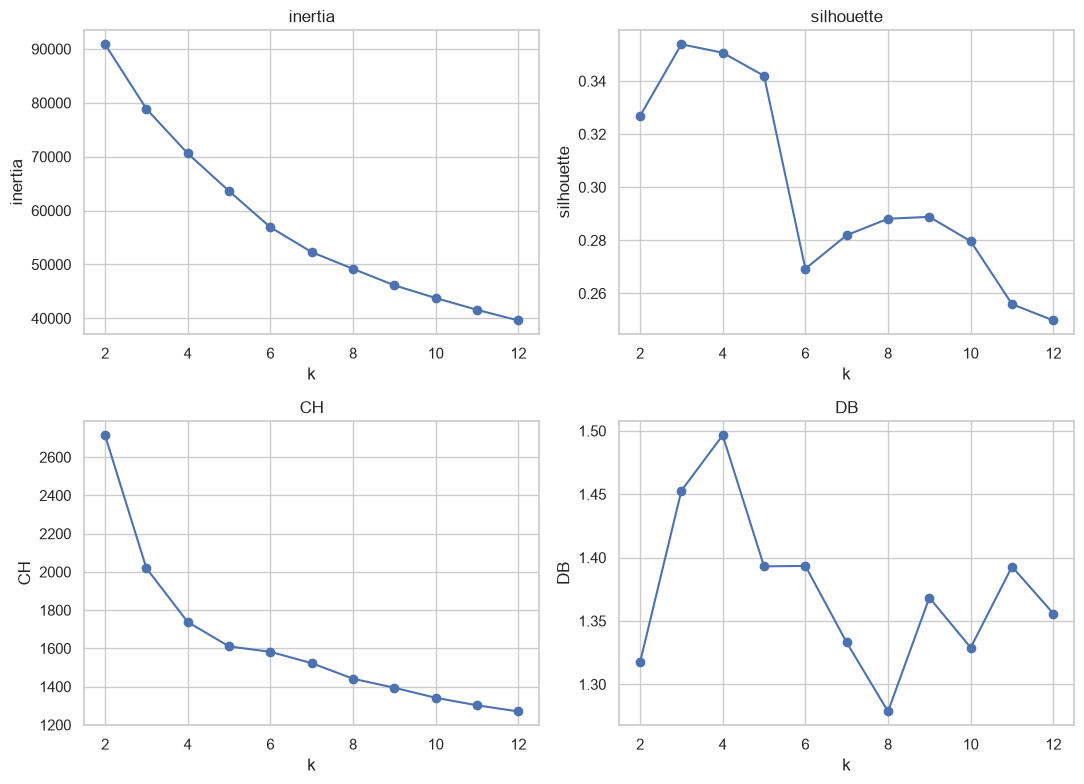

silhouette prefers k=3
CH prefers k=2
DB prefers k=8


In [53]:
# These metrics need not agree: silhouette likes clear separation, CH compares
# between- and within-cluster spread, and DB measures relative overlap.
# Different cluster sizes/shapes and different penalties lead to different choices.

fig, axes = plt.subplots(2, 2, figsize=(11, 8))
for ax, col in zip(axes.flat, ['inertia', 'silhouette', 'CH', 'DB']):
    ax.plot(kmeans_eval.k, kmeans_eval[col], marker='o')
    ax.set(xlabel='k', ylabel=col, title=col)
plt.tight_layout(); plt.show()
for col, fn in [('silhouette','idxmax'), ('CH','idxmax'), ('DB','idxmin')]:
    winner = kmeans_eval.loc[getattr(kmeans_eval[col], fn)(), 'k']
    print(f'{col} prefers k={int(winner)}')

**Notes:** The scores need not choose the same k: silhouette rewards well-separated clusters, CH weighs between/within spread, and DB penalizes clusters that overlap. They also make different assumptions about cluster shape and size.

<details><summary><b>Hint 1</b></summary>

`plt.subplots(2, 2)` and one metric per panel.

</details>
<details><summary><b>Hint 2</b></summary>

`kmeans_eval.loc[kmeans_eval.silhouette.idxmax(), 'k']`; for Davies–Bouldin use `idxmin`.

</details>

### Exercise 9 – Look inside the average: silhouette diagrams

Choose a **compact** and a **richer** candidate from the table (the reference uses `k=4` and `k=9`). For each, fit K-Means, compute the silhouette of every call with `silhouette_samples`, and draw a silhouette diagram: the sorted values of each cluster as a horizontal band, with the mean as a dashed line. Print the cluster sizes and the share of calls with a negative silhouette.

**Explain:** What does the diagram show that the average silhouette hides? Which of your two candidates would you keep for now, and why?

k=4: sizes=[2972  555  515 1958], negative silhouettes=2.1%
k=9: sizes=[1874 1181  434  338 1099   93  267  356  358], negative silhouettes=3.5%


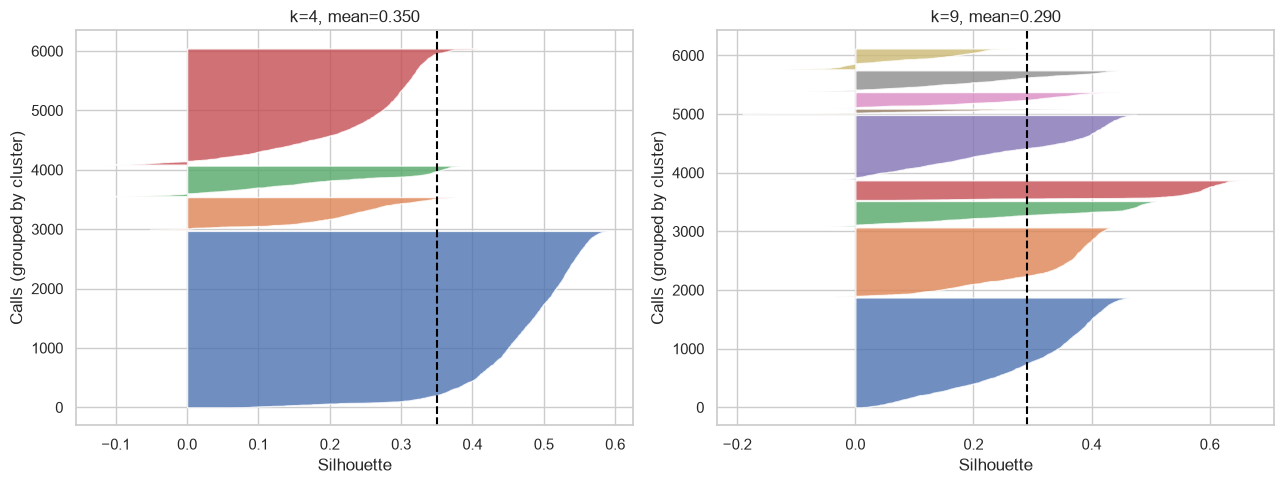

In [54]:
# Silhouette plots show cluster sizes and negative-score calls hidden by the mean.
# Keep k=4 as a simple option and k=9 as a richer candidate for now;
# the larger k might separate more frogs but could also split real groups.

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, k in zip(axes, [4, 9]):
    labels = KMeans(k, n_init=20, random_state=RANDOM_STATE).fit_predict(X_scaled)
    values = silhouette_samples(X_scaled, labels)
    y0 = 0
    for g in range(k):
        vals = np.sort(values[labels == g]); ys = np.arange(y0, y0 + len(vals))
        ax.fill_betweenx(ys, 0, vals, alpha=.8)
        y0 += len(vals) + 15
    ax.axvline(values.mean(), color='black', ls='--')
    ax.set(xlabel='Silhouette', ylabel='Calls (grouped by cluster)', title=f'k={k}, mean={values.mean():.3f}')
    print(f'k={k}: sizes={np.bincount(labels)}, negative silhouettes={(values < 0).mean():.1%}')
plt.tight_layout(); plt.show()

**Notes:** The average hides tiny clusters and calls with negative silhouettes. I would keep both k=4 and k=9 as candidates for now; the richer model may separate more species, but might split natural groups.

<details><summary><b>Hint 1</b></summary>

For cluster `g`: `vals = np.sort(s[labels == g])`, then `ax.fill_betweenx(np.arange(y0, y0 + len(vals)), 0, vals)` and move `y0` down by the cluster's size plus a gap.

</details>
<details><summary><b>Hint 2</b></summary>

A negative silhouette means a call is closer, on average, to another cluster than to its own.

</details>

## Block 3 – Stability: does the answer survive re-running?
A model you can't reproduce is hard to trust. But a reproducible answer isn't necessarily a useful one, and that difference is the point of this block.

### Exercise 10 – Measure clustering stability

For `k` in `{3, 4, 5, 9, 10}`, run K-Means **10 times** with `n_init=1` and random states `0, ..., 9`. For each `k`, report the mean and standard deviation of the inertia, and the mean and minimum pairwise ARI between the 10 clusterings. Store the table as `stability_eval`.

**Note:** here ARI compares *two clusterings with each other*, not a clustering with a reference.

In [55]:
# Compare all 45 pairs of ten different initializations for each k.
# ARI here measures agreement between two clusterings, not agreement with species;
# a low minimum ARI means at least one run landed on a quite different solution.

rows = []
for k in [3, 4, 5, 9, 10]:
    runs, inertias = [], []
    for seed in range(10):
        km = KMeans(k, n_init=1, random_state=seed).fit(X_scaled)
        runs.append(km.labels_); inertias.append(km.inertia_)
    aris = [adjusted_rand_score(a, b) for a, b in combinations(runs, 2)]
    rows.append({'k': k, 'inertia_mean': np.mean(inertias), 'inertia_std': np.std(inertias),
                 'ARI_mean': np.mean(aris), 'ARI_min': np.min(aris)})
stability_eval = pd.DataFrame(rows)
display(stability_eval.round(3))

,k,inertia_mean,inertia_std,ARI_mean,ARI_min
0,3,80829.871,1944.717,0.729,0.478
1,4,72824.830,1787.410,0.636,0.404
2,5,65014.251,1206.074,0.700,0.475
3,9,48223.816,2186.429,0.699,0.495
4,10,45629.688,1682.493,0.733,0.513


<details><summary><b>Hint 1</b></summary>

`combinations(label_runs, 2)` gives the 45 pairs of runs.

</details>
<details><summary><b>Hint 2</b></summary>

`n_init=1` is what makes the runs differ: each run starts from one random set of centres.

</details>

### Exercise 11 – Separate stability from quality

Interpret the stability table together with the internal metrics. Is the `k` with the best silhouette automatically the most stable? Is the most stable solution automatically the most meaningful? Use your actual numbers.

**Expected result (described, no picture or output is shown):** A reasoned answer that uses numbers from your stability and metric tables.

In [56]:
# Compare the best silhouette with the most reproducible k using actual scores.
# Stability does not imply biological quality: a repeatable result could consistently
# group recordings by microphone rather than by frog species.

best_sil = kmeans_eval.loc[kmeans_eval.silhouette.idxmax(), 'k']
most_stable = stability_eval.loc[stability_eval.ARI_mean.idxmax(), 'k']
print(f'Best silhouette: k={int(best_sil)}, score={kmeans_eval.silhouette.max():.3f}')
print(f'Most stable of tested k: k={int(most_stable)}, mean ARI={stability_eval.ARI_mean.max():.3f}')
print('Stability says whether runs agree, not whether they separate species.')

Best silhouette: k=3, score=0.354
Most stable of tested k: k=10, mean ARI=0.733
Stability says whether runs agree, not whether they separate species.


**Notes:** The two choices are not automatically the same. Even a perfectly repeatable grouping could follow the microphone rather than biology.

<details><summary><b>Hint 1</b></summary>

Compare the ranking of k by silhouette with the ranking by mean pairwise ARI.

</details>
<details><summary><b>Hint 2</b></summary>

What would a perfectly repeatable but too coarse clustering be good for?

</details>

## Block 4 – Other algorithms: GMM, Ward and DBSCAN
K-Means is one view. A Gaussian mixture gives a likelihood, Ward builds a hierarchy, and DBSCAN refuses to label sparse calls. Each one changes what "a good clustering" can mean.

**AIC and BIC** both reward fit and penalize parameters; lower is better, and BIC's penalty is heavier when there are many observations.

### Exercise 12 – Compare model complexity with AIC and BIC

Create an 8-component PCA representation `X_pca8` of `X_scaled` (`random_state=RANDOM_STATE`). For `n_components = 2, ..., 12`, fit a **full-covariance** `GaussianMixture` (`n_init=2, reg_covar=1e-5, random_state=RANDOM_STATE`) and record AIC and BIC in `gmm_ic`. Plot both and print each criterion's minimum.

**Explain:** Why can't you compare a BIC value with a silhouette score? Why should a minimum at the edge of the tested range make you cautious?

,k,AIC,BIC
0,2,134222.9,134819.1
1,3,123974.4,124872.1
2,4,120970.7,122170.0
3,5,112657.9,114158.5
4,6,105281.1,107083.3
5,7,102525.1,104628.7
6,8,99432.3,101837.4
7,9,97512.0,100218.6
8,10,96708.6,99716.7
9,11,93722.2,97031.8


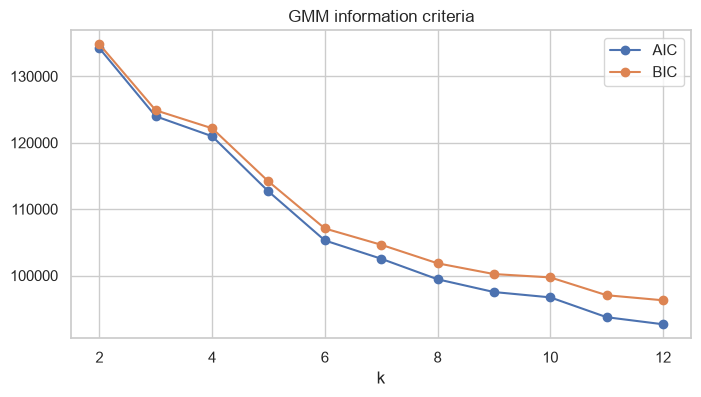

AIC best k: 12
BIC best k: 12


In [57]:
# AIC/BIC measure likelihood fit with a complexity penalty; silhouette measures
# geometric separation, so their values are not on a comparable scale.
# If the minimum is at k=12 (our search boundary), larger k may still improve it.

X_pca8 = PCA(n_components=8, random_state=RANDOM_STATE).fit_transform(X_scaled)

rows = []
for k in range(2, 13):
    gm = GaussianMixture(n_components=k, covariance_type='full', n_init=2,
                         reg_covar=1e-5, random_state=RANDOM_STATE).fit(X_pca8)
    rows.append({'k': k, 'AIC': gm.aic(X_pca8), 'BIC': gm.bic(X_pca8)})
    
gmm_ic = pd.DataFrame(rows)
display(gmm_ic.round(1))
gmm_ic.set_index('k').plot(marker='o', figsize=(8, 4), title='GMM information criteria')
plt.show()
print('AIC best k:', gmm_ic.loc[gmm_ic.AIC.idxmin(), 'k'])
print('BIC best k:', gmm_ic.loc[gmm_ic.BIC.idxmin(), 'k'])

**Notes:** BIC scores model likelihood with a complexity penalty; silhouette measures cluster geometry, so their raw numbers cannot be compared. A best score at k=12 also suggests the tested range may be too narrow.

<details><summary><b>Hint 1</b></summary>

`gmm.aic(X_pca8)` and `gmm.bic(X_pca8)` after `gmm.fit(X_pca8)`.

</details>
<details><summary><b>Hint 2</b></summary>

BIC has no fixed range and depends on the data it was computed on.

</details>

### Exercise 13 – A hierarchy: the Ward dendrogram

Draw a reproducible subset of **2,500 rows** with `np.sort(np.random.default_rng(RANDOM_STATE).choice(len(df), 2500, replace=False))` and store it as `subset_idx`. Build a Ward linkage on `X_pca8[subset_idx]` with `scipy.cluster.hierarchy.linkage` and draw the dendrogram of the last 30 merges. Next to it, plot the merge height against the number of clusters you would get by cutting just below it (2 to 16), and print the three largest jumps.

**Explain:** Where would you cut the tree, and how many clusters does that give? Does the hierarchy suggest one natural number of clusters?

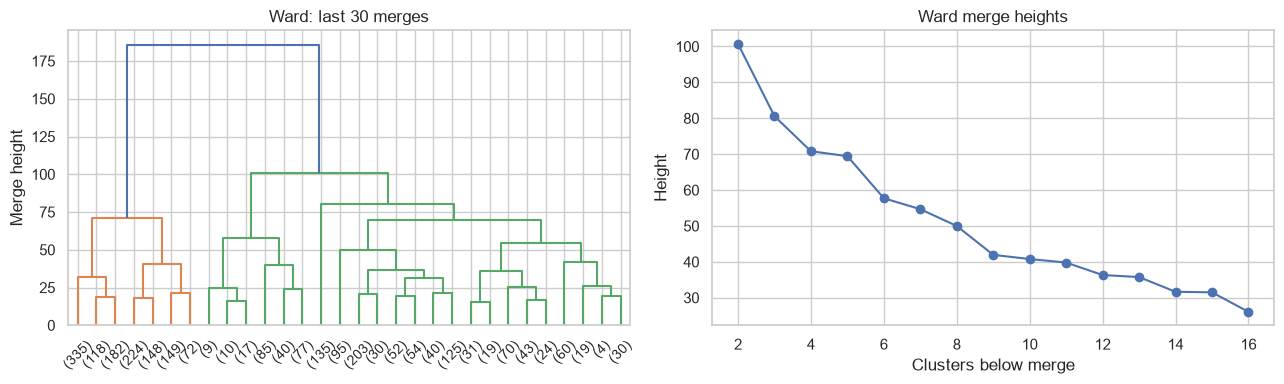

Largest height jumps (k, jump): [(2, np.float64(20.15475293717178)), (5, np.float64(11.720282445992773)), (3, np.float64(9.767254297580564))]


In [58]:
# Ward's largest height jumps give plausible places to cut the dendrogram.
# A big jump suggests a useful cut, but several jumps can be reasonable;
# there is no guarantee of one uniquely correct cluster count.

subset_idx = np.sort(np.random.default_rng(RANDOM_STATE).choice(len(df), 2500, replace=False))
ward_links = linkage(X_pca8[subset_idx], method='ward')

# Plotting
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

# Dendrogram
dendrogram(ward_links, truncate_mode='lastp', p=30, ax=axes[0])
axes[0].set(title='Ward: last 30 merges', ylabel='Merge height')

# Ward line plot
ks = np.arange(2, 17)
heights = np.array([ward_links[-k, 2] for k in ks])
axes[1].plot(ks, heights, marker='o')
axes[1].set(xlabel='Clusters below merge', ylabel='Height', title='Ward merge heights')
plt.tight_layout(); plt.show()

jumps = [(k, ward_links[-k,2] - ward_links[-k-1,2]) for k in range(2, 17)]
print('Largest height jumps (k, jump):', sorted(jumps, key=lambda x: x[1], reverse=True)[:3])

# We would cut the dendrogram at height ≈ 110, giving 2 clusters.
# The largest jump in merge height is between approximately 100 and 185. 
# Cutting within this gap separates the two main branches before they merge.

**Notes:** Large vertical jumps suggest possible cut points, but Ward does not give one unambiguous natural k. I would compare a large-jump cut with the other metrics.

<details><summary><b>Hint 1</b></summary>

`dendrogram(Z_link, truncate_mode='lastp', p=30, no_labels=True, ax=ax)`.

</details>
<details><summary><b>Hint 2</b></summary>

`heights = Z_link[::-1, 2]`: `heights[0]` is the last merge (2 clusters → 1). A big drop from `heights[i]` to `heights[i + 1]` means cutting between them leaves `i + 2` well-separated clusters.

</details>

### Exercise 14 – DBSCAN: density, noise and coverage

On `X_pca8`, compute each call's distance to its 20th **other** nearest neighbour and plot the sorted distances. Run DBSCAN with `min_samples=20` and `eps` at the 50th, 65th, 80th and 90th percentiles of those distances; store the labels in `db_labels[quantile]` and build `dbscan_eval` with the number of clusters (without `-1`), the noise percentage and the silhouette **on the kept rows** (`sample_size=2000`). Plot the cluster count and the noise against the quantile.

**Explain:** What happens as `eps` grows? Why does a silhouette on the kept rows not describe the whole dataset?

,quantile,eps,clusters,noise_pct,silhouette_kept
0,50,0.922,12,30.250,0.417
1,65,1.102,14,21.217,0.373
2,80,1.481,16,10.750,0.350
3,90,2.015,2,5.250,0.336


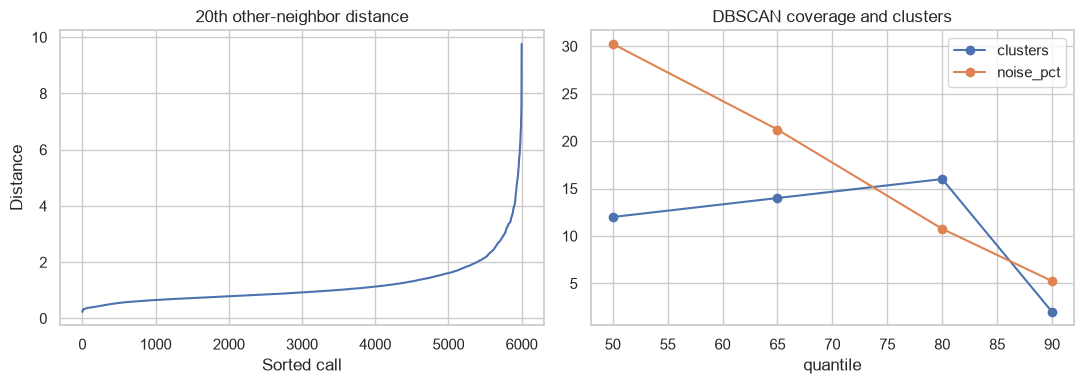

In [59]:

# Check how far each point is from its 20th nearest neighbor
neighbor_dist = NearestNeighbors(n_neighbors=21).fit(X_pca8).kneighbors(X_pca8)[0][:, 20]

# Different percentiles to test for eps
quantiles = [50, 65, 80, 90]

# Store clustering labels and evaluation results
db_labels, rows = {}, []

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

# Plot sorted neighbor distances to help choose eps
axes[0].plot(np.sort(neighbor_dist))
axes[0].set(title='20th other-neighbor distance', xlabel='Sorted call', ylabel='Distance')

# Run DBSCAN with different eps values
for q in quantiles:

    # Choose eps based on the current percentile
    eps = np.percentile(neighbor_dist, q)

    # Apply DBSCAN
    labels = DBSCAN(eps=eps, min_samples=20, n_jobs=-1).fit_predict(X_pca8)
    db_labels[q] = labels

    # Remove noise points (labeled as -1)
    keep = labels != -1

    # Count the number of clusters without noise
    nclusters = len(set(labels[keep]))

    # Calculate silhouette score only for non-noise points
    sil = silhouette_score(
        X_pca8[keep],
        labels[keep],
        sample_size=min(2000, keep.sum()),
        random_state=RANDOM_STATE
    ) if nclusters >= 2 and keep.sum() > nclusters else np.nan

    # Save the results for this eps value
    rows.append({
        'quantile': q,
        'eps': eps,
        'clusters': nclusters,
        'noise_pct': 100 * (~keep).mean(),
        'silhouette_kept': sil
    })

# Create a table with all DBSCAN results
dbscan_eval = pd.DataFrame(rows)
display(dbscan_eval.round(3))

# Compare the number of clusters and noise percentage
dbscan_eval.plot(
    x='quantile',
    y=['clusters', 'noise_pct'],
    ax=axes[1],
    marker='o'
)

axes[1].set(title='DBSCAN coverage and clusters')

plt.tight_layout()
plt.show()



# As eps increases, DBSCAN includes more points in clusters, so the noise
# percentage decreases. Nearby clusters may also merge into larger clusters.

# The silhouette score is calculated only on non-noise points, meaning it
# ignores the rejected recordings. Therefore, a high silhouette score can
# be misleading if a large percentage of the dataset is classified as noise.
# We should consider both silhouette score and noise percentage.

**Notes:** Increasing eps tends to absorb noise and merge clusters. A silhouette measured only on accepted calls ignores the ones DBSCAN could not assign.

<details><summary><b>Hint 1</b></summary>

`NearestNeighbors(n_neighbors=20).fit(X_pca8).kneighbors()` without arguments leaves each row itself out.

</details>
<details><summary><b>Hint 2</b></summary>

`kept = labels != -1`; `-1` is not a cluster, it is DBSCAN refusing to label a row.

</details>

### Exercise 15 – Compare algorithms before seeing any labels

On the same 2,500 rows of `X_pca8` (`Xp_sub = X_pca8[subset_idx]`), compare K-Means, a full-covariance GMM (`n_init=2, reg_covar=1e-5`) and Ward (`AgglomerativeClustering(linkage='ward')`) at `k = 4` and `k = 9`, and DBSCAN at the 65th-percentile radius from Exercise 14 (its labels on the same rows). Build `algorithm_internal` with the coverage, silhouette (`sample_size=1500`), Calinski–Harabasz and Davies–Bouldin – for DBSCAN on its kept rows only.

**Explain:** Imagine the taxonomy file does not exist. Which algorithm and configuration would you deploy, based on internal quality, stability or complexity evidence, and simplicity?

In [60]:
# Use the same subset of recordings for a fair comparison
Xp_sub = X_pca8[subset_idx]

# Store the evaluation results
rows = []

# Compare the algorithms with 4 and 9 clusters
for k in [4, 9]:

    # Run K-Means, GMM and Ward clustering
    models = {
        'K-Means': KMeans(
            k, n_init=20, random_state=RANDOM_STATE
        ).fit_predict(Xp_sub),

        'GMM': GaussianMixture(
            k, covariance_type='full', n_init=2,
            reg_covar=1e-5, random_state=RANDOM_STATE
        ).fit_predict(Xp_sub),

        'Ward': AgglomerativeClustering(
            n_clusters=k, linkage='ward'
        ).fit_predict(Xp_sub)
    }

    # Calculate evaluation metrics for each algorithm
    for name, labels in models.items():
        rows.append({
            'algorithm': name,
            'k': k,
            'coverage': 1.,
            'silhouette': silhouette_score(
                Xp_sub, labels, sample_size=1500,
                random_state=RANDOM_STATE
            ),
            'CH': calinski_harabasz_score(Xp_sub, labels),
            'DB': davies_bouldin_score(Xp_sub, labels)
        })

# Run DBSCAN using eps from the 65th percentile
labels = DBSCAN(
    eps=np.percentile(neighbor_dist, 65),
    min_samples=20
).fit_predict(Xp_sub)

# Exclude noise points from the evaluation
keep = labels != -1

# Evaluate DBSCAN only if it finds at least 2 clusters
if len(set(labels[keep])) >= 2:
    rows.append({
        'algorithm': 'DBSCAN',
        'k': len(set(labels[keep])),
        'coverage': keep.mean(),
        'silhouette': silhouette_score(
            Xp_sub[keep], labels[keep],
            sample_size=min(1500, keep.sum()),
            random_state=RANDOM_STATE
        ),
        'CH': calinski_harabasz_score(Xp_sub[keep], labels[keep]),
        'DB': davies_bouldin_score(Xp_sub[keep], labels[keep])
    })

# Create a table comparing all algorithms
algorithm_internal = pd.DataFrame(rows)
display(algorithm_internal.round(3))

# Find the algorithm with the highest silhouette score
print(
    'Top silhouette on evaluated rows:',
    algorithm_internal.sort_values(
        'silhouette', ascending=False
    ).iloc[0][['algorithm', 'k']].to_dict()
)

# I would choose K-Means with k=9 using background-corrected features.
# It is simple, fast, reproducible and assigns every recording to a cluster.
# Compared to GMM and Ward, it is easier to deploy and computationally cheaper.
# DBSCAN can leave many recordings as noise, making its scores less reliable.
# I would also check cluster stability across different random seeds before deployment.

,algorithm,k,coverage,silhouette,CH,DB
0,K-Means,4,1.00,0.405,931.821,1.167
1,GMM,4,1.00,0.225,717.563,1.653
2,Ward,4,1.00,0.397,897.894,1.183
3,K-Means,9,1.00,0.350,869.351,1.070
4,GMM,9,1.00,0.193,543.151,1.662
5,Ward,9,1.00,0.313,755.462,1.186
6,DBSCAN,7,0.68,0.477,750.480,0.604


Top silhouette on evaluated rows: {'algorithm': 'DBSCAN', 'k': 7}


**Notes:** Without taxonomy, I would start with background-corrected K-Means: it is simple, repeatable and covers every call. A high DBSCAN silhouette needs its coverage reported beside it.

<details><summary><b>Hint 1</b></summary>

Write a small function that takes labels and returns the three scores, so every algorithm is scored the same way.

</details>
<details><summary><b>Hint 2</b></summary>

DBSCAN's row: `db_sub = db_labels[.65][subset_idx]`, scored on `db_sub != -1`.

</details>

## Block 5 – Reveal the taxonomy: external evaluation
From this point on you may open `frog_taxonomy_reveal.csv`. It holds **three nested levels** of taxonomy, which were hidden until now so that they couldn't influence your choices.

**Toolbox:** ARI (agreement between two partitions, corrected for chance), NMI (shared information on a 0–1 scale) and purity. ARI and NMI ignore what the clusters are called.

### Exercise 16 – Reveal and validate the reference labels

Load `data/frog_taxonomy_reveal.csv` and merge it with `df` on `sample_id` (`validate='one_to_one'`) into `df_labeled`. Report the number of families, genera and species, the share of the largest and the smallest species, and the largest number of species in any one session. Store the species as `y_species` and plot the number of calls per species.

In [61]:
# Merge the taxonomy by sample_id to align labels with the cleaned calls.
# Each recording session holds one species, so a random row split later would
# leak information from the same recording into both train and test sets.

taxonomy = pd.read_csv(DATA / 'frog_taxonomy_reveal.csv')
df_labeled = df.merge(taxonomy, on='sample_id', validate='one_to_one')
for col in ['family_group', 'genus_group', 'species_group']:
    print(col, 'groups:', df_labeled[col].nunique())
species_sizes = df_labeled.species_group.value_counts(normalize=True)
print('Largest species share:', round(species_sizes.max(), 3),
      '| smallest:', round(species_sizes.min(), 3))
print('Most species in any session:', df_labeled.groupby('recording_session').species_group.nunique().max())
y_species = df_labeled.species_group
plt.figure(figsize=(9, 4))
df_labeled.species_group.value_counts().plot.bar(title='Calls per species')
plt.ylabel('Calls'); plt.tight_layout(); plt.show()

KeyError: 'sample_id'

**Notes:** Each session holds one species, so sessions are not independent samples of different species.

<details><summary><b>Hint 1</b></summary>

`validate='one_to_one'` raises an error if a `sample_id` appears twice – which is why Exercise 1 dropped the duplicates.

</details>
<details><summary><b>Hint 2</b></summary>

`df_labeled.groupby('recording_session').species_group.nunique().max()`.

</details>

### Exercise 17 – Was your normalization right?

For each matrix in `candidates`, fit K-Means `k=10` and compute the species ARI and NMI and the NMI with `recording_session`. Show them next to the label-free columns of `normalization_eval` from Exercise 5.

**Explain:** Did the label-free evidence of Block 1 lead to the right choice? Which label-free number would have misled you?

In [ ]:
# Now verify the label-free normalization decision using the real species labels.
# A high global silhouette can be misleading: it can reward session artifacts.
# Species ARI/NMI give a better check that the groups reflect biology.

rows = []
for name, X in candidates.items():
    labels = KMeans(10, n_init=20, random_state=RANDOM_STATE).fit_predict(X)
    rows.append({'normalization': name, 'species_ARI': adjusted_rand_score(y_species, labels),
                 'species_NMI': normalized_mutual_info_score(y_species, labels),
                 'session_NMI_check': normalized_mutual_info_score(sessions, labels)})
normalization_external = pd.DataFrame(rows).set_index('normalization')
display(normalization_eval.join(normalization_external).round(3))

,between_session,silhouette,session_nmi,species_ARI,species_NMI,session_NMI_check
normalization,,,,,,
global,0.834,0.272,0.717,0.308,0.556,0.717
session mean,0.000,0.056,0.137,0.064,0.120,0.137
background,0.727,0.280,0.581,0.560,0.658,0.581


**Notes:** The biological labels are the real check on our normalization. Global silhouette alone can be misleading because session effects create visually tidy clusters.

<details><summary><b>Hint 1</b></summary>

Build a small table per normalization and merge it with `normalization_eval` on the `normalization` column.

</details>
<details><summary><b>Hint 2</b></summary>

Compare the ranking by silhouette with the ranking by species ARI.

</details>

### Exercise 18 – Why "adjusted"? Rand index, mutual information and entropy

Fit K-Means `k=10` on `X_scaled` and call the labels `lab10`. Make a **completely random labeling** with 10 groups (`np.random.default_rng(RANDOM_STATE).integers(0, 10, len(df))`). For both against `y_species`, print the raw Rand index (`rand_score`), ARI, raw mutual information (`mutual_info_score`) and NMI. Also print the entropy of the species and of `lab10` (`scipy.stats.entropy` on their proportions), and compare it with `ln 10`.

**Explain:** What score does a random labeling get on each measure? Why do we use the adjusted or normalized versions? What does the species entropy say about the classes?

In [ ]:
# A random labeling can still get positive raw Rand and mutual-information scores.
# ARI adjusts for chance, while NMI rescales MI for easier comparison.
# Species entropy describes label diversity: a lower value indicates imbalance.

lab10 = KMeans(10, n_init=20, random_state=RANDOM_STATE).fit_predict(X_scaled)
random_labels = np.random.default_rng(RANDOM_STATE).integers(0, 10, len(df))
for name, labels in [('K-Means', lab10), ('Random', random_labels)]:
    print(name, '| Rand:', round(rand_score(y_species, labels), 3),
          '| ARI:', round(adjusted_rand_score(y_species, labels), 3),
          '| MI:', round(mutual_info_score(y_species, labels), 3),
          '| NMI:', round(normalized_mutual_info_score(y_species, labels), 3))
print('Species entropy:', entropy(y_species.value_counts(normalize=True)).round(3))
print('Cluster entropy:', round(entropy(pd.Series(lab10).value_counts(normalize=True)), 3),
      '| ln(10):', round(np.log(10), 3))

K-Means | Rand: 0.843 | ARI: 0.56 | MI: 1.214 | NMI: 0.658
Random | Rand: 0.674 | ARI: 0.0 | MI: 0.008 | NMI: 0.004
Species entropy: 1.677
Cluster entropy: 2.012 | ln(10): 2.303


**Notes:** Chance can produce a positive raw Rand or mutual information score. Adjusted/normalized measures help interpret agreement; the species entropy also reflects how balanced the true classes are.

<details><summary><b>Hint 1</b></summary>

`entropy(y_species.value_counts(normalize=True))`.

</details>
<details><summary><b>Hint 2</b></summary>

For 10 equally large groups the entropy would be `np.log(10)`.

</details>

### Exercise 19 – Evaluate against three ground truths

For K-Means with `k = 2, ..., 12` on `X_scaled`, compute ARI and NMI against each taxonomy level and store them in one table `external_eval`. Plot NMI and ARI against `k` (one panel each, three lines), and print the best `k` for each level and each score.

**Explain:** Compare the best `k` values with the number of groups at each level and with the internally preferred `k` from Block 2. Why can ARI and NMI prefer different `k`?

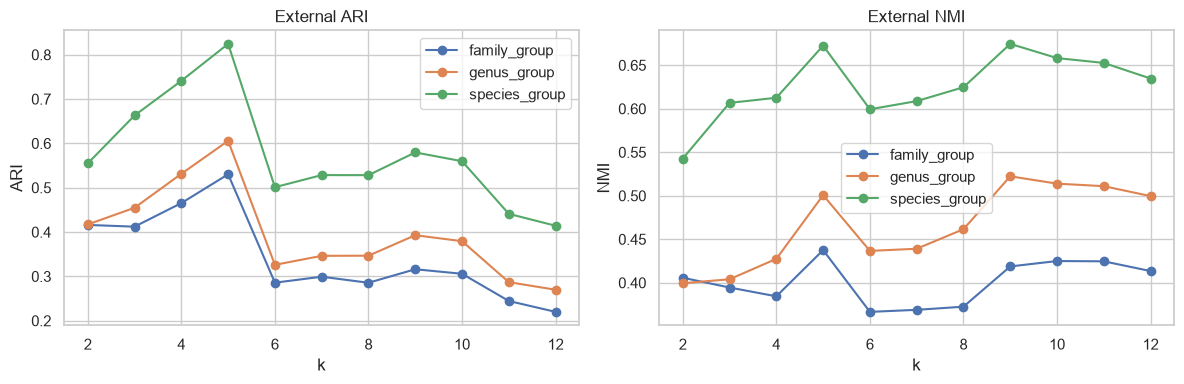

family_group | groups: 4 | best ARI k: 5 | best NMI k: 5
genus_group | groups: 8 | best ARI k: 5 | best NMI k: 9
species_group | groups: 10 | best ARI k: 5 | best NMI k: 9


In [ ]:
# Family, genus and species are different target resolutions, so their best k
# need not equal one another or the internally chosen k.
# ARI emphasizes pairwise agreement; NMI emphasizes shared information,
# which can make them favor different cluster counts.

levels = ['family_group', 'genus_group', 'species_group']
rows = []
for k in range(2, 13):
    labels = KMeans(k, n_init=20, random_state=RANDOM_STATE).fit_predict(X_scaled)
    for level in levels:
        truth = df_labeled[level]
        rows.append({'k': k, 'level': level, 'ARI': adjusted_rand_score(truth, labels),
                     'NMI': normalized_mutual_info_score(truth, labels)})
external_eval = pd.DataFrame(rows)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, metric in zip(axes, ['ARI', 'NMI']):
    for level in levels:
        tmp = external_eval.query('level == @level')
        ax.plot(tmp.k, tmp[metric], marker='o', label=level)
    ax.set(xlabel='k', ylabel=metric, title=f'External {metric}'); ax.legend()
plt.tight_layout(); plt.show()
for level in levels:
    tmp = external_eval.query('level == @level')
    print(level, '| groups:', df_labeled[level].nunique(),
          '| best ARI k:', int(tmp.loc[tmp.ARI.idxmax(), 'k']),
          '| best NMI k:', int(tmp.loc[tmp.NMI.idxmax(), 'k']))

**Notes:** A family may contain several species, so the best k depends on the taxonomy level. ARI and NMI reward different kinds of agreement and may favor different cluster counts.

<details><summary><b>Hint 1</b></summary>

Loop over `k`, fit once, then loop over the three levels: `df_labeled[f'{level}_group']`.

</details>
<details><summary><b>Hint 2</b></summary>

ARI counts *pairs* of calls. Which species contributes most of the pairs?

</details>

### Exercise 20 – Inspect where the score comes from

For `lab10`, draw the contingency table of clusters against `y_species` as an annotated heatmap. Map every cluster to its **most common species** (a many-to-one mapping), report the purity (the accuracy of that mapping) and the species that are the majority of no cluster, and print a `classification_report` of the mapped labels (`zero_division=0`).

**Explain:** Find one species split across several clusters and one species that is never a majority. Why can purity be high while some species are never recovered?

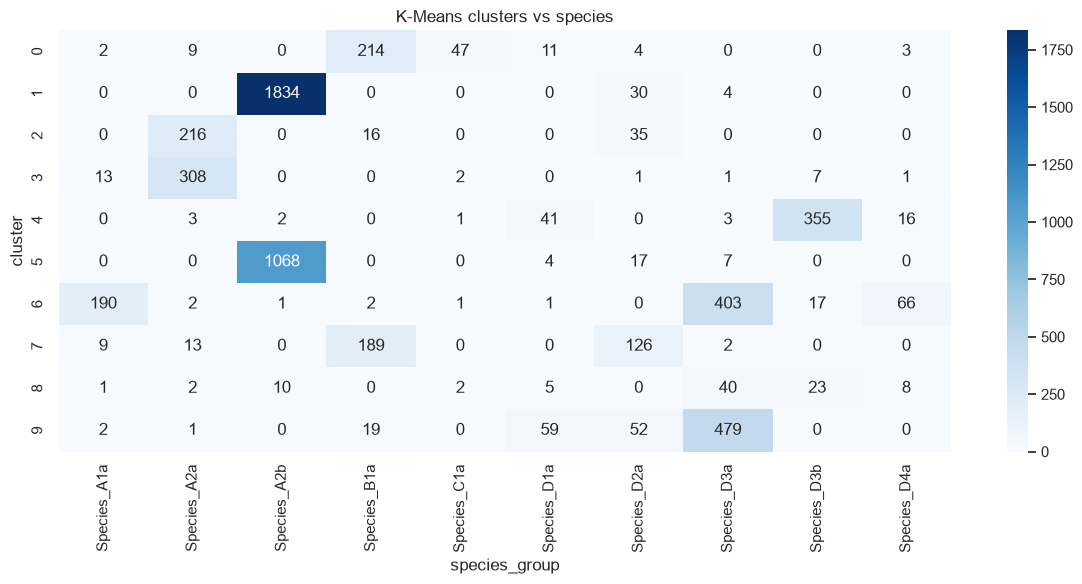

Purity: 0.851
Species never majority: ['Species_A1a', 'Species_C1a', 'Species_D1a', 'Species_D2a', 'Species_D4a']
              precision    recall  f1-score   support

 Species_A1a       0.00      0.00      0.00       217
 Species_A2a       0.87      0.95      0.91       554
 Species_A2b       0.98      1.00      0.99      2915
 Species_B1a       0.64      0.92      0.75       440
 Species_C1a       0.00      0.00      0.00        53
 Species_D1a       0.00      0.00      0.00       121
 Species_D2a       0.00      0.00      0.00       265
 Species_D3a       0.67      0.98      0.79       939
 Species_D3b       0.84      0.88      0.86       402
 Species_D4a       0.00      0.00      0.00        94

    accuracy                           0.85      6000
   macro avg       0.40      0.47      0.43      6000
weighted avg       0.76      0.85      0.80      6000

Species spread over the most clusters: {'Species_A2a': 8, 'Species_D3a': 8, 'Species_D2a': 7}


In [ ]:
# Purity assigns each cluster its majority species, allowing many clusters to
# vote for the same species. That can give high purity even if a rare species
# is split up or never becomes the majority in any cluster.

contingency = pd.crosstab(pd.Series(lab10, name='cluster'), y_species)
plt.figure(figsize=(12, 6))
sns.heatmap(contingency, annot=True, fmt='d', cmap='Blues')
plt.title('K-Means clusters vs species'); plt.tight_layout(); plt.show()
majority = contingency.idxmax(axis=1)
mapped_species = pd.Series(lab10).map(majority)
purity = (mapped_species.to_numpy() == y_species.to_numpy()).mean()
missing_majorities = sorted(set(y_species) - set(majority))
print('Purity:', round(purity, 3))
print('Species never majority:', missing_majorities)
print(classification_report(y_species, mapped_species, zero_division=0))
print('Species spread over the most clusters:', (contingency > 0).sum().sort_values(ascending=False).head(3).to_dict())

**Notes:** Purity is generous: several clusters may map to the same species. That can give high purity while a less common species is never any cluster's majority.

<details><summary><b>Hint 1</b></summary>

`ct.idxmax(axis=1)` gives each cluster's majority species; `pd.Series(lab10).map(majority)` gives a predicted species per call.

</details>
<details><summary><b>Hint 2</b></summary>

Purity rewards every cluster for its majority. Can a small species be the majority anywhere?

</details>

### Exercise 21 – Look at the map

On the 2,500 rows of `subset_idx`, fit a 2D t-SNE of `X_scaled` (`perplexity=40, init='pca', learning_rate='auto', random_state=RANDOM_STATE, **TSNE_ITER`). Draw three panels of the same map, coloured by `lab10`, by species, and by session (`plot_sessions`). Print the NMI of `lab10` with the species and with the session on these rows.

**Explain:** What are the islands of the map made of – clusters, species or sessions? What does that mean for a clustering of *new* recordings?

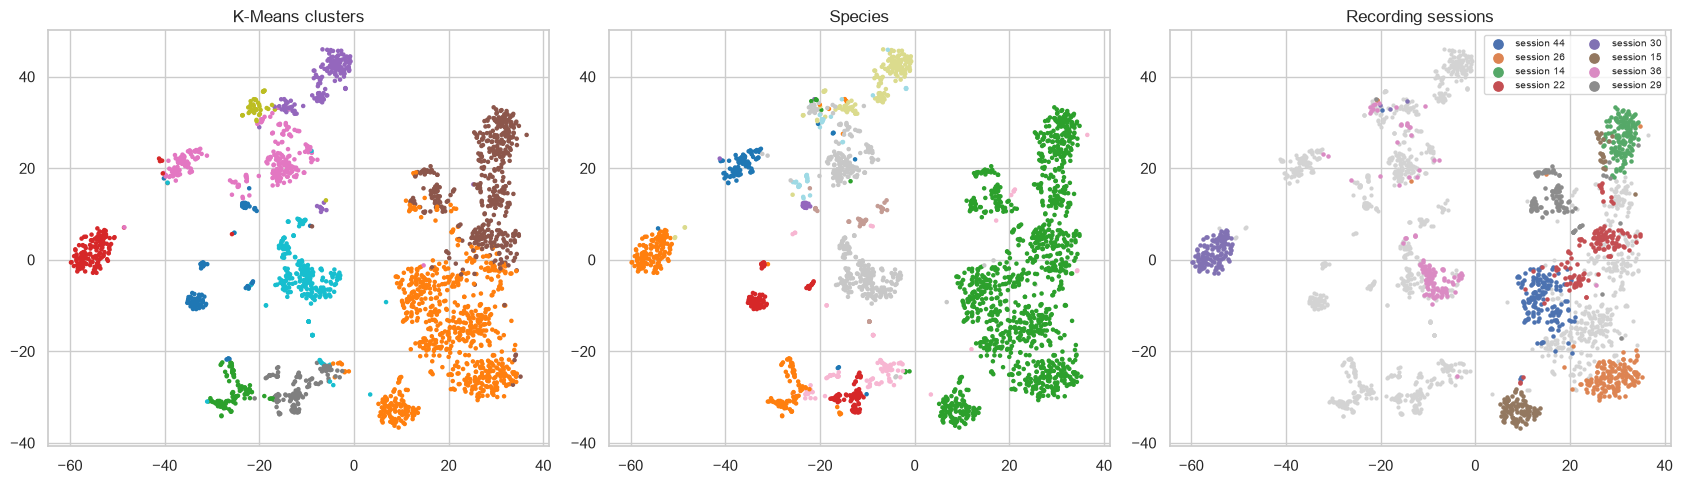

Subset NMI cluster/species: 0.663
Subset NMI cluster/session: 0.587


In [ ]:
# t-SNE places locally similar calls nearby, but its islands are not necessarily species.
# Compare cluster, species and session coloring of the exact same map.
# Session-shaped islands may not generalize to brand-new recordings.

Z_tsne = TSNE(n_components=2, perplexity=40, init='pca', learning_rate='auto',
              random_state=RANDOM_STATE, **TSNE_ITER).fit_transform(X_scaled[subset_idx])
fig, axes = plt.subplots(1, 3, figsize=(17, 5))
axes[0].scatter(*Z_tsne.T, c=lab10[subset_idx], cmap='tab10', s=5)
axes[0].set_title('K-Means clusters')
species_codes = pd.Categorical(y_species.iloc[subset_idx]).codes
axes[1].scatter(*Z_tsne.T, c=species_codes, cmap='tab20', s=5)
axes[1].set_title('Species')
plot_sessions(axes[2], Z_tsne, sessions[subset_idx], 'Recording sessions')
plt.tight_layout(); plt.show()
print('Subset NMI cluster/species:', round(normalized_mutual_info_score(y_species.iloc[subset_idx], lab10[subset_idx]), 3))
print('Subset NMI cluster/session:', round(normalized_mutual_info_score(sessions[subset_idx], lab10[subset_idx]), 3))

**Notes:** t-SNE islands show local similarity, not guaranteed biological classes. Session overlap matters when considering predictions on completely new recordings.

<details><summary><b>Hint 1</b></summary>

For the species panel, loop over the species and scatter each one with its own label.

</details>
<details><summary><b>Hint 2</b></summary>

t-SNE keeps each call's nearest neighbours close. Who are a call's nearest neighbours, most of the time?

</details>

## Block 6 – Leakage and new recording sessions
So far, higher scores have looked like good news. This block is about when they aren't – and about testing the model the way it will be used: on recordings it has never heard.

### Exercise 22 – Test the recording-session metadata trap

Repeat K-Means `k=10`, but this time **incorrectly add `recording_session` as a numeric feature** to the background-subtracted calls, and standardize everything together. Compare the correct and the incorrect model by silhouette, species ARI and species NMI.

**Explain:** Did the wrong feature make the scores better or worse, and why is that dangerous?

In [ ]:
# This is intentionally wrong: session IDs are arbitrary numbers, not sounds.
# Even if adding them improves an internal or external score, the model can learn
# an identifier shortcut that will not transfer to new recording sessions.

X_wrong = StandardScaler().fit_transform(pd.DataFrame(
    np.column_stack([call_values - background_mean.loc[sessions, feature_cols].to_numpy(), sessions])))
wrong_labels = KMeans(10, n_init=20, random_state=RANDOM_STATE).fit_predict(X_wrong)
trap = pd.DataFrame([
    {'model': 'acoustic only', 'silhouette': silhouette_score(X_scaled, lab10, sample_size=2000, random_state=RANDOM_STATE),
     'species_ARI': adjusted_rand_score(y_species, lab10), 'species_NMI': normalized_mutual_info_score(y_species, lab10)},
    {'model': 'with session ID', 'silhouette': silhouette_score(X_wrong, wrong_labels, sample_size=2000, random_state=RANDOM_STATE),
     'species_ARI': adjusted_rand_score(y_species, wrong_labels), 'species_NMI': normalized_mutual_info_score(y_species, wrong_labels)}])
display(trap.round(3))

,model,silhouette,species_ARI,species_NMI
0,acoustic only,0.280,0.560,0.658
1,with session ID,0.261,0.557,0.654


**Notes:** Session numbers are arbitrary identifiers, not continuous measurements. Even if adding them improves a score, it is leakage-like behavior that would not generalize to unseen session IDs.

<details><summary><b>Hint 1</b></summary>

`np.column_stack([background-subtracted calls, sessions])`, then `StandardScaler`.

</details>
<details><summary><b>Hint 2</b></summary>

Each session holds one species. What can a session number tell the model about the answer?

</details>

### Exercise 23 – Evaluate on unseen sessions

Use `GroupShuffleSplit(n_splits=5, test_size=0.25, random_state=RANDOM_STATE)` with the sessions as groups, so that whole sessions are held out. For every split and every normalization (`global`, `session mean`, `background`): fit the scaler and K-Means `k=10` **on the training rows only**, predict the held-out rows, and compute the species ARI and NMI. Report the mean and standard deviation per normalization and plot the ARI of every split. Keep the first split's `train_idx` and `test_idx`.

**Explain:** Is each normalization usable on a new recording? How large is the difference between normalizations compared with the variation between splits?

ARI           NMI       
                mean    std   mean    std
normalization                            
background     0.581  0.164  0.653  0.048
global         0.424  0.080  0.562  0.077
session mean   0.062  0.025  0.102  0.035

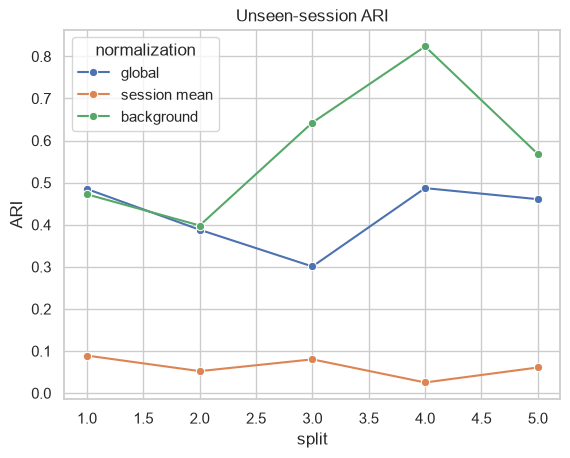

In [ ]:
# Split whole sessions, not individual calls, and fit the scaler on training data only.
# Global scaling needs no background for a new call; session-mean needs many calls
# from that recording; background subtraction needs its silence measurement.
# Compare the gaps between methods with the variability across the five splits.

gss = GroupShuffleSplit(n_splits=5, test_size=.25, random_state=RANDOM_STATE)
rows = []
for split, (tr, te) in enumerate(gss.split(df, groups=sessions), 1):
    if split == 1:
        train_idx, test_idx = tr, te
    for name in ['global', 'session mean', 'background']:
        train_raw, test_raw = call_values[tr].copy(), call_values[te].copy()
        if name == 'session mean':
            # Each held-out session can be normalized from its own calls.
            tr_mean = df.iloc[tr].groupby('recording_session')[feature_cols].transform('mean').to_numpy()
            te_mean = df.iloc[te].groupby('recording_session')[feature_cols].transform('mean').to_numpy()
            train_raw -= tr_mean; test_raw -= te_mean
        elif name == 'background':
            train_raw -= background_mean.loc[sessions[tr], feature_cols].to_numpy()
            test_raw -= background_mean.loc[sessions[te], feature_cols].to_numpy()
        scaler = StandardScaler().fit(train_raw)
        km = KMeans(10, n_init=20, random_state=RANDOM_STATE).fit(scaler.transform(train_raw))
        pred = km.predict(scaler.transform(test_raw))
        rows.append({'split': split, 'normalization': name,
                     'ARI': adjusted_rand_score(y_species.iloc[te], pred),
                     'NMI': normalized_mutual_info_score(y_species.iloc[te], pred)})
heldout_eval = pd.DataFrame(rows)
display(heldout_eval.groupby('normalization')[['ARI','NMI']].agg(['mean','std']).round(3))
sns.lineplot(data=heldout_eval, x='split', y='ARI', hue='normalization', marker='o')
plt.title('Unseen-session ARI'); plt.show()

**Notes:** Group splits prevent calls from a held-out recording appearing in training. Global works immediately; session-mean needs all the new recording's calls; background normalization needs its background recording. Split-to-split variation also matters.

<details><summary><b>Hint 1</b></summary>

Build the three *unscaled* inputs first (raw, minus session mean, minus background); fit `StandardScaler` inside the loop on `M[train_idx]`.

</details>
<details><summary><b>Hint 2</b></summary>

A new session comes with its own background segments and its own calls, so both subtractions can be computed for it without any label.

</details>

### Exercise 24 – Recognize grouped data

Why is a group-based split more informative than a random split of individual calls, when many calls come from the same recording session? Give one example of another dataset where the same principle applies.

**Expected result (described, no picture or output is shown):** An explanation and one example from another domain.

In [ ]:
# Calls from one recording are correlated, so a random row split leaks session
# information into the test set and looks too optimistic.
# Group splitting is also important for repeated visits from one patient.

print('A random row split puts calls from the same recording in both sets.')
print('Splitting by session tests generalization to genuinely new recordings.')
print('The same rule applies to multiple measurements from the same patient.')

A random row split puts calls from the same recording in both sets.
Splitting by session tests generalization to genuinely new recordings.
The same rule applies to multiple measurements from the same patient.


<details><summary><b>Hint 1</b></summary>

With a random split, where do the other calls of a test call's recording end up?

</details>
<details><summary><b>Hint 2</b></summary>

Think of repeated measurements of the same patient, user, machine or video.

</details>

## Block 7 – Find the bug
Three checks. In all of them the code **runs without an error** and the conclusion is still wrong.

**How to hunt a silent bug:** (1) compare the result with a number you trust; (2) ask what the score actually measures; (3) ask what would have to be true for this comparison to be fair.

### Exercise 25 – Only 0.5% accurate?

A colleague scores your k=10 clustering against the species and reports: *"The clustering is less than 1% accurate, so it is useless."* Show what is wrong, give the agreement with appropriate scores, and compute the accuracy **after** matching each cluster to one species (`linear_sum_assignment` on the crosstab).

**Expected result (described, no picture or output is shown):** The raw accuracy, ARI and NMI, the accuracy after a one-to-one matching, the purity from Exercise 20, and one sentence on why the first number means nothing.

In [ ]:
# The bug is treating arbitrary K-Means cluster IDs as species code numbers.
# Report ARI/NMI instead, and use Hungarian matching for one-to-one accuracy.
# Purity is more generous because multiple clusters may map to one species.

species_codes = y_species.astype('category').cat.codes.to_numpy()
raw_accuracy = (species_codes == lab10).mean()
table = pd.crosstab(pd.Series(lab10, name='cluster'), y_species)
ri, ci = linear_sum_assignment(table.to_numpy(), maximize=True)
matched_accuracy = table.to_numpy()[ri, ci].sum() / len(df)
print('Naive code equality:', round(raw_accuracy, 3))
print('ARI:', round(adjusted_rand_score(y_species, lab10), 3),
      '| NMI:', round(normalized_mutual_info_score(y_species, lab10), 3))
print('One-to-one matched accuracy:', round(matched_accuracy, 3), '| majority purity:', round(purity, 3))

Naive code equality: 0.005
ARI: 0.56 | NMI: 0.658
One-to-one matched accuracy: 0.586 | majority purity: 0.851


**Bug:** Cluster IDs have no connection to species codes. The Hungarian matching aligns names fairly; purity permits many clusters to map to one species.

<details><summary><b>Hint 1</b></summary>

Does cluster 3 have anything to do with the third species in alphabetical order?

</details>
<details><summary><b>Hint 2</b></summary>

`linear_sum_assignment(table, maximize=True)` pairs each cluster with a different species so that the matched counts are as large as possible.

</details>

### Exercise 26 – Perfectly stable!

A colleague tests the stability of k=10 and reports: *"ARI between runs is 1.000, so k=10 is perfectly stable."* Find the bug and give the honest number.

**Expected result (described, no picture or output is shown):** The ARI between two different seeds, the mean pairwise ARI from your stability table, and a one-sentence correction.

In [ ]:
# Using the same random seed twice tests determinism, not stability.
# Use different seeds with n_init=1 and compare the ARI of those runs;
# the ten-run mean summarizes stability more honestly.

run_a = KMeans(10, n_init=1, random_state=0).fit_predict(X_scaled)
run_b = KMeans(10, n_init=1, random_state=1).fit_predict(X_scaled)
print('ARI between seeds 0 and 1:', round(adjusted_rand_score(run_a, run_b), 3))
print('Mean ARI over ten runs:', round(stability_eval.set_index('k').loc[10, 'ARI_mean'], 3))

ARI between seeds 0 and 1: 0.882
Mean ARI over ten runs: 0.733


**Bug:** Running with the same seed twice proves determinism, not stability across initializations.

<details><summary><b>Hint 1</b></summary>

What is different between the two runs?

</details>
<details><summary><b>Hint 2</b></summary>

A stability test has to change something between runs.

</details>

### Exercise 27 – The microphones don't matter?

A colleague tries the background correction and reports: *"Subtracting the background barely changes the clustering – the NMI with the session only drops from 0.71 to 0.69 – so the microphones don't matter."* Find the bug and give the honest comparison.

**Expected result (described, no picture or output is shown):** For global standardization, the colleague's pipeline and the correct background pipeline: the share of variance between sessions, the NMI with the session and the species ARI of K-Means `k=10`; then one sentence on the bug.

In [ ]:
# The bug is subtracting raw MFCC background values from standardized calls:
# those quantities are in different units. Subtract the background first,
# then fit StandardScaler, and compare session NMI and species ARI again.

X_std = StandardScaler().fit_transform(df[feature_cols])
X_bug = X_std - background_mean.loc[sessions, feature_cols].to_numpy()
X_correct = StandardScaler().fit_transform(
    df[feature_cols].to_numpy() - background_mean.loc[sessions, feature_cols].to_numpy())
rows = []
for name, X in [('global', X_std), ('mixed units (wrong)', X_bug), ('background then scale', X_correct)]:
    labels = KMeans(10, n_init=20, random_state=RANDOM_STATE).fit_predict(X)
    rows.append({'pipeline': name, 'between_session': share_between(X, sessions),
                 'session_NMI': normalized_mutual_info_score(sessions, labels),
                 'species_ARI': adjusted_rand_score(y_species, labels)})
display(pd.DataFrame(rows).round(3))

,pipeline,between_session,session_NMI,species_ARI
0,global,0.834,0.717,0.308
1,mixed units (wrong),0.800,0.660,0.427
2,background then scale,0.727,0.581,0.560


**Bug:** The colleague subtracts raw MFCC background values from standardized calls. The units are incompatible; subtraction must happen before fitting the scaler.

<details><summary><b>Hint 1</b></summary>

In which units is `X_std`, and in which units is `background_mean`?

</details>
<details><summary><b>Hint 2</b></summary>

Subtract first, in the units the background was measured in, and standardize afterwards.

</details>

## Block 8 – Integrated challenge: the evaluation report
**The task.** The biologists ask: *which model should we use to sort new recordings by species, and how far can we trust it?* Answer them with evidence from all the earlier blocks.

### Exercise 28 – Write the evaluation report

Write a **3–5 paragraph technical conclusion** answering all of the following:

1. How should new recordings be normalized, and what evidence – before and after the labels – supports it?
2. Which `k` and which algorithm looked best before the labels were revealed, and why?
3. How did the answer change when the family, genus and species labels were revealed, and what did stability and AIC/BIC add that silhouette alone did not?
4. What did the `recording_session` experiments (the leakage trap and the held-out sessions) teach?
5. For **species sorting on new recording sessions**, which configuration would you recommend, and which limitation would you report?

Refer to **specific numbers or plots** from your notebook.

**Expected result (described, no picture or output is shown):** A 3–5 paragraph conclusion that answers all five questions and cites specific numbers from your notebook.

In [ ]:
# Conclusion: normalize new sessions by subtracting their recorded background,
# then apply a scaler fitted only on the training calls. This addresses microphone
# offsets without erasing the frog's mean sound as session-mean subtraction does.
# Internal scores, stability and AIC/BIC describe different properties: none alone
# tells us the biological number of species or the best deployable clustering.
# Compare cluster labels with family, genus and species only after the reveal;
# scores can change with taxonomy level and may disagree across ARI/NMI.
# A random call split leaks recording effects. Held-out sessions are a better test,
# and performance should be presented with its split-to-split variation.
# The recommendation is conditional: new recordings need comparable background
# samples, and the method may still struggle with unseen frogs or recording setups.

# Report the supporting numbers alongside the written conclusion below.
print('Normalization comparison:'); display(normalization_eval.join(normalization_external).round(3))
print('Internal k choices:'); display(kmeans_eval.sort_values('silhouette', ascending=False).head(3).round(3))
print('Stability:'); display(stability_eval.round(3))
print('Species agreement by algorithm:'); display(external_eval.query("level == 'species_group'").sort_values('ARI', ascending=False).head(3).round(3))
print('Held-out session scores:'); display(heldout_eval.groupby('normalization')[['ARI','NMI']].agg(['mean','std']).round(3))

Normalization comparison:


,between_session,silhouette,session_nmi,species_ARI,species_NMI,session_NMI_check
normalization,,,,,,
global,0.834,0.272,0.717,0.308,0.556,0.717
session mean,0.000,0.056,0.137,0.064,0.120,0.137
background,0.727,0.280,0.581,0.560,0.658,0.581


Internal k choices:


,k,inertia,silhouette,CH,DB
1,3,78883.685,0.354,2019.039,1.453
2,4,70606.953,0.351,1737.849,1.497
3,5,63632.717,0.342,1610.264,1.393


Stability:


,k,inertia_mean,inertia_std,ARI_mean,ARI_min
0,3,80829.871,1944.717,0.729,0.478
1,4,72824.830,1787.410,0.636,0.404
2,5,65014.251,1206.074,0.700,0.475
3,9,48223.816,2186.429,0.699,0.495
4,10,45629.688,1682.493,0.733,0.513


Species agreement by algorithm:


,k,level,ARI,NMI
11,5,species_group,0.824,0.673
8,4,species_group,0.741,0.613
5,3,species_group,0.663,0.607


Held-out session scores:


ARI           NMI       
                mean    std   mean    std
normalization                            
background     0.581  0.164  0.653  0.048
global         0.424  0.080  0.562  0.077
session mean   0.062  0.025  0.102  0.035

**Evaluation report**

For future recordings I would subtract the measured background of each session and then use a scaler fitted on training calls. Global scaling left **83.4%** of the variance between sessions and had a session NMI of **0.717**, compared with **72.7%** and **0.581** after background subtraction. Session-mean subtraction removed nearly all session structure, but it also removed much of the signal that distinguishes individual frogs.

Without the taxonomy, I would start with background-corrected K-Means as a simple baseline. On the full data, silhouette preferred **k=3 (0.354)**, while the k=4 and k=9 models offered more detailed partitions. On the 2,500-row comparison, K-Means k=4 reached **0.405 silhouette**, compared with **0.397** for Ward k=4; DBSCAN reached **0.477**, but only covered **68%** of calls. Ten single-start K-Means runs gave mean pairwise ARIs from **0.636 to 0.733**, showing noticeable instability. GMM AIC and BIC both kept improving up to the tested boundary, k=12, but that is not proof of 12 species.

The labels revealed **4 families, 8 genera and 10 species**. Species ARI was highest at **k=5**, whereas species NMI preferred **k=9**. This explains why the best geometric score need not be the best biological result. The contingency table also showed that majority-vote purity can hide species that never become the majority in any cluster. Including the numeric session ID is not a valid shortcut: it introduces recording metadata into a supposedly acoustic model.

For actual sorting of unseen recordings, I would evaluate background-corrected K-Means with whole-session held-out tests rather than random individual calls. Across five group splits, its species **ARI was 0.581 ± 0.164** and **NMI was 0.653 ± 0.048**, compared with ARI **0.424 ± 0.080** for global scaling and **0.062 ± 0.025** for session-mean subtraction. I would recommend the background-corrected approach as the tested baseline, with a warning that performance varies by recording and requires background data for each new session.

<details><summary><b>Hint 1</b></summary>

Start from the normalization: everything after it depends on it.

</details>
<details><summary><b>Hint 2</b></summary>

Every claim gets a number: a score, a share, a count of sessions.

</details>

## Block 9 – Working with an LLM, critically
You may use ChatGPT, Claude, Gemini or Copilot in this course. The rule is: **you are responsible for every line and every claim**. Below are two prompts, each with a typical answer. The code runs, the output looks reasonable, and each answer is wrong in several ways that only the data can reveal.

For each exercise, do four things: (a) copy the model's code into a new cell and run it, to see its output; (b) find what is wrong, and print **a number from the data that proves each problem**; (c) in the cell below, write the corrected code; (d) write in a comment the one lesson you take from it.

### Exercise 29 – LLM answer 1: how many species?

**Prompt:** *"Here is `frog_calls.csv`. How many frog species are in this file?"*

The model's answer is shown below. **Run it in a new cell.** Find **at least three** flaws, and for each one print a number that proves it (for example: which columns it used, what controls its distances, what its clusters agree with). Then write a corrected version.

**Expected result (described, no picture or output is shown):** Printed numbers that prove at least three flaws, each with a short comment, followed by a corrected result.

**Typical LLM answer. Copy it into a new cell and run it, to see its output. It reads the raw file again, so it does not use your tables; do not trust its result:**

```python
import pandas as pd
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

raw = pd.read_csv('data/frog_calls.csv')
numeric = raw.select_dtypes('number')
scores = {k: silhouette_score(numeric, KMeans(k, n_init=10, random_state=42).fit_predict(numeric),
                              sample_size=2000, random_state=42) for k in range(2, 13)}
print({k: round(v, 3) for k, v in scores.items()})
print('Best k:', max(scores, key=scores.get))
# Conclusion: the highest silhouette tells us how many species there are in this file.
```

In [ ]:
# Flaw 1: selecting all numeric columns accidentally includes the session ID.
# Flaw 2: rereading the original CSV keeps the exact duplicate observations.
# Flaw 3: the silhouette optimum is not evidence for the true number of species.
# Correct approach: use cleaned MFCCs, proper background normalization and
# evaluate biological agreement only when the revealed labels are available.

raw = pd.read_csv(DATA / 'frog_calls.csv')
numeric = raw.select_dtypes('number')
print('Original numeric columns:', numeric.columns.tolist())
print('Fraction of total variance from session ID:', round(numeric.recording_session.var() / numeric.var().sum(), 4))
print('Rows before and after deduplication:', len(raw), len(df))
raw_labels = KMeans(10, n_init=10, random_state=RANDOM_STATE).fit_predict(numeric)
print('Flawed raw clustering NMI with session:', round(normalized_mutual_info_score(raw.recording_session, raw_labels), 3))
print('Correct background clustering NMI with session:', round(normalized_mutual_info_score(sessions, lab10), 3))
print('Correct approach: use nonconstant MFCCs, clean duplicates, normalize, compare several k values.')
print('Taxonomy reveals', y_species.nunique(), 'species; silhouette by itself cannot establish this count.')

Original numeric columns: ['recording_session', 'mfcc_01', 'mfcc_02', 'mfcc_03', 'mfcc_04', 'mfcc_05', 'mfcc_06', 'mfcc_07', 'mfcc_08', 'mfcc_09', 'mfcc_10', 'mfcc_11', 'mfcc_12', 'mfcc_13', 'mfcc_14', 'mfcc_15', 'mfcc_16', 'mfcc_17', 'mfcc_18', 'mfcc_19', 'mfcc_20', 'mfcc_21', 'mfcc_22']
Fraction of total variance from session ID: 0.9952
Rows before and after deduplication: 6025 6000
Flawed raw clustering NMI with session: 0.78
Correct background clustering NMI with session: 0.581
Correct approach: use nonconstant MFCCs, clean duplicates, normalize, compare several k values.
Taxonomy reveals 10 species; silhouette by itself cannot establish this count.


**Three flaws:** The raw numeric columns include session ID, the 25 duplicate records were kept, and silhouette estimates geometric separation rather than the biological species count. The variance share and session NMI above show the metadata problem.

<details><summary><b>Hint 1</b></summary>

Print `numeric.columns` and `numeric.var() / numeric.var().sum()`. Which column decides the distances?

</details>
<details><summary><b>Hint 2</b></summary>

How many rows does `raw` have, and how many did you keep in Exercise 1?

</details>
<details><summary><b>Hint 3</b></summary>

Compare its clusters with `recording_session` and with the species.

</details>

### Exercise 30 – LLM answer 2: standard audio normalization and a clean test set

**Prompt:** *"I want to know if my frog clustering will work on future recordings. Use the standard audio normalization and evaluate it properly with a test set."*

The model's answer is shown below; it continues from your notebook and uses `df` and `y_species`. **Run it in a new cell.** Explain **what is wrong with it statistically** and with its conclusion, and print a number that proves each problem. Then write the corrected version.

**Expected result (described, no picture or output is shown):** Printed numbers that show the effect of the normalization, the session overlap between training and test, and the honest held-out result; then a sentence on what can and cannot be concluded.

**Typical LLM answer. Copy it into a new cell and run it, to see its output. It continues from your notebook and uses your `df` and `y_species`; do not trust its result:**

```python
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

feats = [c for c in df.columns if c.startswith('mfcc_')]
# Cepstral mean normalization: the standard way to remove microphone effects from audio features.
X_cmn = StandardScaler().fit_transform(df[feats] - df.groupby('recording_session')[feats].transform('mean'))
X_tr, X_te, y_tr, y_te = train_test_split(X_cmn, y_species, test_size=0.25, random_state=42)
best = max(range(2, 13), key=lambda k: adjusted_rand_score(y_te, KMeans(k, n_init=10, random_state=42).fit(X_tr).predict(X_te)))
model = KMeans(best, n_init=10, random_state=42).fit(X_tr)
print('Best k:', best, '| Test ARI:', round(adjusted_rand_score(y_te, model.predict(X_te)), 3))
# Conclusion: microphone effects are removed and this is a clean test score, so we know how well it will work on future recordings.
```

In [ ]:
# Flaw 1: subtracting each session's mean call can erase frog identity.
# Flaw 2: a random row split places the same sessions in both sets (leakage).
# Flaw 3: choosing k by test-species ARI improperly tunes on test labels.
# Correct approach: group-split sessions, fit preprocessing on train only,
# and keep the held-out session labels for final evaluation, not tuning.

# Demonstrate the leaky row split from the proposed answer.
indices = np.arange(len(df))
tr_rows, te_rows = train_test_split(indices, test_size=.25, random_state=RANDOM_STATE)
overlap = set(sessions[tr_rows]) & set(sessions[te_rows])
print('Overlapping sessions in random row split:', len(overlap), 'of', len(set(sessions[te_rows])))
print('Session-mean vs background species ARI:',
      normalization_external.loc['session mean', 'species_ARI'].round(3),
      normalization_external.loc['background', 'species_ARI'].round(3))
print('Honest held-out background scores:')
display(heldout_eval.query("normalization == 'background'")[['split','ARI','NMI']].round(3))
print('Correct evaluation uses group splits, a training-only scaler, and no species-based k selection on the test set.')

Overlapping sessions in random row split: 57 of 57
Session-mean vs background species ARI: 0.064 0.56
Honest held-out background scores:


,split,ARI,NMI
2,1,0.472,0.629
5,2,0.398,0.580
8,3,0.643,0.670
11,4,0.824,0.697
14,5,0.568,0.688


Correct evaluation uses group splits, a training-only scaler, and no species-based k selection on the test set.


**Three flaws:** Session-mean subtraction can erase frog identity, random row splitting leaks recording-specific information, and choosing k by *test* ARI uses labels that would not be known at deployment. Held-out sessions give a more realistic estimate.

<details><summary><b>Hint 1</b></summary>

Each recording holds one frog. What does subtracting a recording's mean call remove besides the microphone?

</details>
<details><summary><b>Hint 2</b></summary>

How many test sessions also appear in training with a random row split?

</details>
<details><summary><b>Hint 3</b></summary>

Which data chose `best`?

</details>

## Block 10 – Further investigations ★ (extra)
Every exercise in this block is marked with ★: they are extra, for whoever finishes early.

### Exercise 31 – Do AIC and BIC find the species? ★

For `k` in `3, 5, 10, 12`, fit the same GMM as in Exercise 12 on `X_pca8` and K-Means on `X_scaled`, and compare their species ARI and NMI in one table.

**Explain:** AIC and BIC preferred k=12. Is the GMM there better at finding species than K-Means, or than a smaller GMM? What does that say about using BIC to answer the biologists' question?

In [ ]:
# AIC/BIC select acoustic likelihood fit, not biological species recovery.
# Even if BIC prefers k=12, a smaller GMM or K-Means may give better species
# ARI/NMI, which matters more for the biologists' actual task.

rows = []
for k in [3, 5, 10, 12]:
    gm = GaussianMixture(k, covariance_type='full', n_init=2, reg_covar=1e-5,
                         random_state=RANDOM_STATE).fit_predict(X_pca8)
    km = KMeans(k, n_init=20, random_state=RANDOM_STATE).fit_predict(X_scaled)
    rows.append({'k': k, 'GMM_ARI': adjusted_rand_score(y_species, gm),
                 'GMM_NMI': normalized_mutual_info_score(y_species, gm),
                 'KMeans_ARI': adjusted_rand_score(y_species, km),
                 'KMeans_NMI': normalized_mutual_info_score(y_species, km)})
extra_gmm = pd.DataFrame(rows)
display(extra_gmm.round(3))

,k,GMM_ARI,GMM_NMI,KMeans_ARI,KMeans_NMI
0,3,0.692,0.589,0.663,0.607
1,5,0.460,0.551,0.824,0.673
2,10,0.525,0.630,0.560,0.658
3,12,0.441,0.646,0.414,0.635


**Notes:** AIC/BIC optimize fit to acoustic data, not species agreement. A smaller GMM or K-Means can be better for the biologists even when k=12 has the best BIC.

<details><summary><b>Hint 1</b></summary>

Reuse the GMM settings of Exercise 12: `covariance_type='full', n_init=2, reg_covar=1e-5`.

</details>
<details><summary><b>Hint 2</b></summary>

Put both algorithms in one row per k.

</details>

### Exercise 32 – Evaluating DBSCAN against the taxonomy ★

For every quantile in `db_labels`, report the number of clusters, the coverage, and the species ARI and NMI **on the kept rows only**, together with the NMI with `recording_session` on the same rows and the smallest share of any species that DBSCAN keeps.

**Explain:** Is a near-perfect score on the kept rows a reason to prefer DBSCAN? What would you report next to it?

In [ ]:
# A near-perfect species score on assigned calls may hide poor coverage.
# DBSCAN can reject many recordings, possibly most of a particular species.
# Always report overall and worst-species coverage beside kept-only scores.

rows = []
for q, labels in db_labels.items():
    keep = labels != -1
    species_coverage = pd.Series(keep).groupby(y_species.to_numpy()).mean()
    nclust = len(set(labels[keep]))
    rows.append({'quantile': q, 'clusters': nclust, 'coverage': keep.mean(),
                 'species_ARI_kept': adjusted_rand_score(y_species[keep], labels[keep]) if keep.any() else np.nan,
                 'species_NMI_kept': normalized_mutual_info_score(y_species[keep], labels[keep]) if keep.any() else np.nan,
                 'session_NMI_kept': normalized_mutual_info_score(sessions[keep], labels[keep]) if keep.any() else np.nan,
                 'worst_species_coverage': species_coverage.min()})
db_external = pd.DataFrame(rows)
display(db_external.round(3))

,quantile,clusters,coverage,species_ARI_kept,species_NMI_kept,session_NMI_kept,worst_species_coverage
0,50,12,0.698,0.995,0.964,0.606,0.000
1,65,14,0.788,0.966,0.903,0.627,0.106
2,80,16,0.892,0.948,0.871,0.641,0.419
3,90,2,0.948,0.011,0.027,0.028,0.762


**Notes:** Great scores on accepted calls can still be unfair if DBSCAN rejects many calls or almost all calls from one species. Coverage and worst-species coverage belong beside the score.

<details><summary><b>Hint 1</b></summary>

`kept = labels != -1`, then score `y_species[kept]` against `labels[kept]`.

</details>
<details><summary><b>Hint 2</b></summary>

`pd.Series(kept).groupby(y_species.to_numpy()).mean().min()` is the coverage of the worst-covered species.

</details>

### Exercise 33 – Can BIC choose the representation? ★

A colleague wants to choose how many PCA components to keep for the GMM and argues: *"BIC is much lower with 3 components than with 8, so 3 is the better representation."* For 8, 5, 3, 2 and 1 components, fit a 10-component GMM (settings of Exercise 12) and report its BIC and its species NMI.

**Explain:** Why can't BIC compare models fitted to different data?

In [ ]:
# BIC is based on the likelihood of the data that the model was fitted on.
# One-, three- and eight-dimensional PCA inputs are different data spaces;
# their raw BIC values cannot be compared as a representation ranking.
# Check an external criterion such as species NMI separately.

rows = []
for d in [8, 5, 3, 2, 1]:
    Z = PCA(n_components=d, random_state=RANDOM_STATE).fit_transform(X_scaled)
    gm = GaussianMixture(10, covariance_type='full', n_init=2, reg_covar=1e-5,
                         random_state=RANDOM_STATE).fit(Z)
    rows.append({'PCs': d, 'BIC': gm.bic(Z),
                 'species_NMI': normalized_mutual_info_score(y_species, gm.predict(Z))})
pca_bic_comparison = pd.DataFrame(rows)
display(pca_bic_comparison.round(3))

,PCs,BIC,species_NMI
0,8,99716.695,0.630
1,5,79510.909,0.603
2,3,59737.090,0.622
3,2,44206.334,0.562
4,1,23089.050,0.485


**Notes:** BIC values on 1D, 3D and 8D data describe different likelihood spaces and cannot rank the representations directly. Species NMI is a separate external check.

<details><summary><b>Hint 1</b></summary>

Refit PCA with `n_components=n` each time, then the GMM on that representation.

</details>
<details><summary><b>Hint 2</b></summary>

BIC is the likelihood of *the data it was given*. Is a table with fewer columns the same data?

</details>

# **Good Job :)**

Before you submit: make sure every cell runs top to bottom (Kernel ▸ Restart & Run All), and check that the PDF shows the same figures, tables and reasoning as the notebook.